# Replicate health and compound activity

**Question:** do the compounds and doses capture real biology? We ask four things: do the replicate wells of a treatment agree with each other, which treatments change the cells compared with DMSO, how the change depends on dose and time, and which treatments look alike.

Words used in this notebook:

- **Replicate wells:** the 3 wells of the same treatment and dose, on the same plate and cell line.
- **Null distribution:** the scores we get from wells that are *not* replicates. A real result must beat the null.
- **Replicate correlation and percent replicating:** how similar the 3 replicate profiles are (Pearson correlation across all features), compared with the null. Percent replicating is the share of treatments that beat the 95th percentile of the null.
- **mAP (mean average precision):** for each replicate well, we rank all other wells by similarity and ask whether its replicates come before the DMSO wells. mAP is 1 when the replicates always come first, and about 0.02 (3 replicates among 127 DMSO wells) by chance. A permutation test gives a p-value. A treatment with significant mAP is **active**: its wells are reproducibly different from DMSO.
- **Consensus profile:** the median of the 3 replicate profiles.

Every comparison is made within one plate (time point) and one cell line, against the DMSO wells of that same plate and cell line, because time and exposure settings cannot be separated, and cell line and plate side cannot be separated.

## Setup

Run on the login node or with `_run.sbatch` (about 3 minutes, a few GB of memory).

In [1]:
import os
import pathlib

# setting the number of threads for parallel processing
# few threads are enough for 1,140 wells
n_threads = 8
os.environ["POLARS_MAX_THREADS"] = str(n_threads)
os.environ["OMP_NUM_THREADS"] = str(n_threads)
os.environ["NUMBA_NUM_THREADS"] = str(n_threads)

import mantispy as mt
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap, LogNorm, TwoSlopeNorm
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle
from scipy import stats
from scipy.cluster import hierarchy
from scipy.spatial.distance import squareform

In [2]:
# input: the QCed well profiles of the preprocessing module
profiles_path = pathlib.Path("../2.preprocessing/results/qced_agg_norm_fs_Panc1_hPSC_well-profiles.parquet").resolve(strict=True)

# outputs of this notebook
fig_dir = pathlib.Path("results/figures/03.replicate-health-diagnosis").resolve()
table_dir = pathlib.Path("results/tables/03.replicate-health-diagnosis").resolve()
fig_dir.mkdir(parents=True, exist_ok=True)
table_dir.mkdir(parents=True, exist_ok=True)

seed = 0
rng = np.random.default_rng(seed)
# values beyond this many MADs are set to the limit, so a few extreme features cannot dominate
clip_limit = 20
# random draws for each null distribution
n_null = 10_000
# fewer draws for the DMSO-set distances, because each draw takes a median over ~124 wells
n_null_sets = 2_000
# a score is "above chance" when it beats this quantile of its null
null_quantile = 0.95
# false discovery rate for the mAP activity call
fdr = 0.05
# a DMSO well is "unusual" when its distance from the DMSO centre is above the median + 3 MAD of all DMSO wells
unusual_mads = 3
# a profile "looks like the unusual DMSO wells" when it correlates with their median profile at least this much
artifact_corr = 0.8

# fixed orders and colors, the same as in the other notebooks
plate_order = ["1h", "4h", "24h"]
line_order = ["CL1", "CL2"]
panels = [(time, line) for time in plate_order for line in line_order]
agent_order = ["CBK041498", "CBK175924", "CBK200566", "CBK600005", "CBK600008", "TGFb1", "IL6"]
ligands = ["TGFb1", "IL6"]
dose_order = {agent: (["L", "M", "H"] if agent in ligands else ["0.2", "0.67", "2.0"]) for agent in agent_order}
perturbation_order = [f"{agent}_{dose}" for agent in agent_order for dose in dose_order[agent]]
dose_level = {"0.2": 0, "0.67": 1, "2.0": 2, "L": 0, "M": 1, "H": 2}
# compound doses are stock concentrations; the final well concentration is unknown
dose_text = {"0.2": "0.2 mM", "0.67": "0.67 mM", "2.0": "2 mM", "L": "2.5 ng/ml", "M": "5 ng/ml", "H": "10 ng/ml"}

# setting the same colors for the two cell lines and three time points in all figures
line_colors = {"CL1": "#6250d6", "CL2": "#eda100"}
plate_colors = {"1h": "#2a78d6", "4h": "#eb6834", "24h": "#1baf7a"}
well_type_colors = {"control": "#a5a5a5", "compound": "#1baf7a", "ligand": "#d03b3b"}
blues = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#2a78d6", "#0d366b"])

sns.set_theme(style="ticks", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})


def pretty(perturbation):
    # readable treatment name, e.g. "CBK041498 0.2 mM"
    agent, dose = perturbation.split("_")
    return f"{agent} {dose_text[dose]}"


def save_figure(fig, name):
    # every figure is saved for the report, then shown
    fig.savefig(fig_dir / f"{name}.png", dpi=200, bbox_inches="tight")
    plt.show()


def panel_filter(time, line):
    # the wells of one plate (time point) and one cell line
    return (pl.col("Metadata_time_point") == time) & (pl.col("Metadata_cell_line") == line)

## 1. Load the well profiles

Each well profile is the median of its QC-passing cells. Features were normalized against the DMSO cells of the same plate and cell line, so 0 means "like DMSO".

The preprocessing also marks each well as passing or failing a well QC (`Metadata_well_qc`): a well fails when fewer than 100 of its cells pass cell QC, or when more than 10% of its values are missing. We leave failed wells out of every analysis below, and show them in grey on the plate maps.

**Pass if:** few wells fail, and every treatment keeps at least 2 of its 3 wells per plate and cell line.

In [3]:
adata = mt.io.read_profiles(profiles_path, resolution="well")
print(f"{adata.n_obs:,} wells x {adata.n_vars:,} features")


def well_table(obs):
    # well metadata as a polars table; "row" is the row of the well in the feature matrix
    return (
        pl.from_pandas(obs.reset_index(drop=True))
    .with_columns(pl.col(pl.Categorical).cast(pl.Utf8))
    .with_row_index("row")
    .with_columns(
        pl.col("Metadata_time_point").cast(pl.Enum(plate_order)),
        pl.col("Metadata_Perturbation").str.split("_").list.first().alias("agent"),
        pl.col("Metadata_Perturbation").str.split("_").list.get(1, null_on_oob=True).alias("dose"),
        pl.col("Metadata_CellCount").cast(pl.Int64),
    )
    .with_columns(pl.col("dose").replace_strict(dose_level, default=None).alias("dose_level"))
    )


# wells that fail well QC are listed, kept for the plate maps, and left out of the analysis
all_wells = well_table(adata.obs)
failed_wells = all_wells.filter(pl.col("Metadata_well_qc") != "pass").sort("Metadata_time_point", "Metadata_cell_line", "Metadata_Well")
failed_wells.select(
    "Metadata_time_point", "Metadata_cell_line", "Metadata_Well", "Metadata_Perturbation", "Metadata_CellCount", "Metadata_well_qc_reason"
).write_csv(table_dir / "failed_qc_wells.csv")
print(f"wells failing well QC: {failed_wells.height} of {all_wells.height}")
with pl.Config(tbl_rows=100, tbl_width_chars=200, fmt_str_lengths=80):
    print(failed_wells.select("Metadata_time_point", "Metadata_cell_line", "Metadata_Well", "Metadata_Perturbation", "Metadata_CellCount", "Metadata_well_qc_reason"))

adata = adata[(adata.obs["Metadata_well_qc"].astype(str) == "pass").to_numpy()].copy()
features = adata.var_names.to_list()
meta = well_table(adata.obs)
print(f"analysed: {adata.n_obs:,} wells x {adata.n_vars:,} features")

design = (
    meta.group_by("Metadata_time_point", "Metadata_cell_line")
    .agg(
        (pl.col("agent") == "DMSO").sum().alias("DMSO wells"),
        (pl.col("agent") != "DMSO").sum().alias("treated wells"),
        pl.col("Metadata_Perturbation").filter(pl.col("agent") != "DMSO").n_unique().alias("treatments"),
        pl.col("Metadata_CellCount").median().alias("median cells per well"),
    )
    .sort("Metadata_time_point", "Metadata_cell_line")
)
print(design)
replicates_per_treatment = (
    meta.filter(pl.col("agent") != "DMSO").group_by("Metadata_time_point", "Metadata_cell_line", "Metadata_Perturbation").len()
)
print("wells per treatment, plate and cell line:", dict(replicates_per_treatment["len"].value_counts().sort("len").iter_rows()))
with pl.Config(tbl_rows=50):
    print("treatments with fewer than 3 wells left:")
    print(replicates_per_treatment.filter(pl.col("len") < 3).sort("Metadata_time_point", "Metadata_cell_line", "Metadata_Perturbation"))

1,140 wells x 1,399 features
wells failing well QC: 4 of 1140
shape: (4, 6)
┌─────────────────────┬────────────────────┬───────────────┬───────────────────────┬────────────────────┬─────────────────────────┐
│ Metadata_time_point ┆ Metadata_cell_line ┆ Metadata_Well ┆ Metadata_Perturbation ┆ Metadata_CellCount ┆ Metadata_well_qc_reason │
│ ---                 ┆ ---                ┆ ---           ┆ ---                   ┆ ---                ┆ ---                     │
│ enum                ┆ str                ┆ str           ┆ str                   ┆ i64                ┆ str                     │
╞═════════════════════╪════════════════════╪═══════════════╪═══════════════════════╪════════════════════╪═════════════════════════╡
│ 24h                 ┆ CL1                ┆ L04           ┆ DMSO                  ┆ 89                 ┆ fewer than 100 cells    │
│ 24h                 ┆ CL1                ┆ N03           ┆ CBK175924_0.67        ┆ 76                 ┆ fewer than 100 cells    │


### Clip and rescale the features

1. **Clip.** Features with almost no spread in the DMSO cells can get huge normalized values. The preprocessing drops the worst of them, but we still set any value beyond ±20 to ±20, and report how often that happens.
2. **Rescale to the DMSO wells.** The features were scaled by the spread between DMSO *cells*. The spread between DMSO *wells* is much smaller and differs between features, so a few noisy features would dominate every distance. For each plate and cell line, we subtract the median DMSO well and divide by the spread of the DMSO wells (1.4826 × MAD). A value of 3 now means "3 times the normal well-to-well variation of DMSO". We clip again at ±20.

All correlations, distances and clusters below use these clipped, rescaled profiles.

In [4]:
raw = adata.X.astype(np.float64)
extreme = np.abs(raw) > clip_limit
print(f"input: largest |value| {np.abs(raw).max():,.1f}; {extreme.sum():,} values ({100 * extreme.mean():.4f}%) beyond ±{clip_limit}, in {extreme.any(axis=0).sum()} features and {extreme.any(axis=1).sum()} wells")
clipped = np.clip(raw, -clip_limit, clip_limit)

profiles = np.empty_like(clipped)
for time, line in panels:
    rows = meta.filter(panel_filter(time, line))["row"].to_numpy()
    dmso = clipped[meta.filter(panel_filter(time, line) & (pl.col("agent") == "DMSO"))["row"].to_numpy()]
    centre = np.median(dmso, axis=0)
    spread = 1.4826 * np.median(np.abs(dmso - centre), axis=0)
    # a few features hardly vary between DMSO wells; a floor stops them from blowing up
    spread = np.maximum(spread, np.quantile(spread[spread > 0], 0.01))
    profiles[rows] = (clipped[rows] - centre) / spread

extreme = np.abs(profiles) > clip_limit
print(f"rescaled: {100 * extreme.mean():.2f}% of values beyond ±{clip_limit} (clipped), in {extreme.any(axis=0).sum()} features")
profiles = np.clip(profiles, -clip_limit, clip_limit)

# distance of each well from the DMSO centre (the centre is 0 after rescaling)
meta = meta.with_columns(pl.Series("distance", np.linalg.norm(profiles, axis=1)))

input: largest |value| 44.1; 48 values (0.0030%) beyond ±20, in 14 features and 21 wells
rescaled: 0.08% of values beyond ±20 (clipped), in 443 features


**Result:**

- 1,140 wells × 1,399 features. 4 wells fail well QC, all on the 24h plate in CL1 with fewer than 100 cells: 2 DMSO wells (L04, N10), and one well each of CBK175924 0.67 mM (N03) and 2 mM (N08). We leave them out, so 1,136 wells remain, and these two CBK175924 treatments keep 2 wells.
- Only 48 input values (0.003%, in 14 features; largest 44) were beyond ±20 and were clipped.
- After rescaling to the DMSO well-to-well spread, 0.08% of the values were beyond ±20 and were clipped.

## 2. Replicate reproducibility

**Percent replicating.** For each treatment, plate and cell line, the replicate correlation is the median of the 3 pairwise correlations between its 3 wells (or the single correlation, when well QC left only 2 wells; it is then compared with a null of 2 wells). The null draws 3 wells from 3 *different* treatments on the same plate and cell line (DMSO counts as one treatment), 10,000 times. A treatment "replicates" when its replicate correlation is above the 95th percentile of the null.

**Negative control check:** sets of 3 random DMSO wells should beat the threshold only about 5% of the time.

**How to read the figure:** each panel has the null on top (grey) and, below it, one row per agent with one dot per dose (light and small = low dose, dark and large = high dose). A dot right of the dashed line, with a black outline, is a treatment whose wells agree more than chance.

**Pass if:** DMSO sets pass about 5% of the time, and treatments pass more often than that.

In [5]:
def median_pair_corr(corr, wells):
    # median of the pairwise correlations between the wells (3 pairs for 3 wells, 1 pair for 2)
    wells = np.asarray(wells)
    a, b = np.triu_indices(len(wells), 1)
    return np.median(corr[wells[a], wells[b]])


replicate_rows, null_scores, dmso_scores, corr_thresholds = [], {}, {}, {}
for time, line in panels:
    panel = meta.filter(panel_filter(time, line))
    corr = np.corrcoef(profiles[panel["row"].to_numpy()])
    labels = panel["Metadata_Perturbation"].to_numpy()
    wells_of = {p: np.flatnonzero(labels == p) for p in np.unique(labels)}
    groups = list(wells_of)

    # null: wells of different perturbations, so they are never replicates; one null per group size
    # (3 wells, or 2 wells for a treatment that lost a well to well QC)
    thresholds = {}
    for size in (2, 3):
        size_null = np.array([
            median_pair_corr(corr, [rng.choice(wells_of[p]) for p in rng.choice(groups, size, replace=False)])
            for _ in range(n_null)
        ])
        thresholds[size] = np.quantile(size_null, null_quantile)
        if size == 3:
            null = size_null
    threshold = thresholds[3]
    # negative control: random sets of 3 DMSO wells
    dmso = np.array([median_pair_corr(corr, rng.choice(wells_of["DMSO"], 3, replace=False)) for _ in range(n_null)])
    null_scores[(time, line)], dmso_scores[(time, line)], corr_thresholds[(time, line)] = null, dmso, threshold

    for perturbation in groups:
        if perturbation == "DMSO":
            continue
        n_wells = len(wells_of[perturbation])
        # a treatment with a single well left cannot be tested for reproducibility
        score = median_pair_corr(corr, wells_of[perturbation]) if n_wells >= 2 else None
        replicate_rows.append({
            "time_point": time, "cell_line": line, "perturbation": perturbation, "n_wells": n_wells,
            "wells": ", ".join(panel["Metadata_Well"].to_numpy()[wells_of[perturbation]]),
            "replicate_corr": score, "corr_threshold": thresholds.get(n_wells),
            "replicating": bool(score > thresholds[n_wells]) if score is not None else None,
        })

scores = pl.DataFrame(replicate_rows).with_columns(
    pl.col("time_point").cast(pl.Enum(plate_order)),
    pl.col("perturbation").str.split("_").list.first().alias("agent"),
    pl.col("perturbation").str.split("_").list.get(1).alias("dose"),
).with_columns(
    pl.when(pl.col("agent").is_in(ligands)).then(pl.lit("ligand")).otherwise(pl.lit("compound")).alias("well_type"),
    pl.col("dose").replace_strict(dose_level).alias("dose_level"),
)

for time, line in panels:
    sub = scores.filter((pl.col("time_point") == time) & (pl.col("cell_line") == line))
    print(
        f"{time:>3} {line}: threshold r = {corr_thresholds[(time, line)]:.2f}, "
        f"{sub['replicating'].sum()}/{sub['replicating'].count()} treatments replicate ({100 * sub['replicating'].mean():.0f}%), "
        f"DMSO sets pass {100 * (dmso_scores[(time, line)] > corr_thresholds[(time, line)]).mean():.1f}%"
    )
print(f"all plates: {scores['replicating'].sum()}/{scores['replicating'].count()} ({100 * scores['replicating'].mean():.0f}%); not testable (1 well left): {scores['replicating'].null_count()}")

 1h CL1: threshold r = 0.42, 4/21 treatments replicate (19%), DMSO sets pass 4.9%
 1h CL2: threshold r = 0.30, 4/21 treatments replicate (19%), DMSO sets pass 4.9%
 4h CL1: threshold r = 0.39, 7/21 treatments replicate (33%), DMSO sets pass 4.6%
 4h CL2: threshold r = 0.34, 9/21 treatments replicate (43%), DMSO sets pass 8.4%
24h CL1: threshold r = 0.42, 7/21 treatments replicate (33%), DMSO sets pass 4.8%
24h CL2: threshold r = 0.41, 12/21 treatments replicate (57%), DMSO sets pass 4.8%
all plates: 43/126 (34%); not testable (1 well left): 0


**mAP against DMSO.** We use `mantispy.tl.map` (activity mode, cosine distance) on the rescaled profiles. Each replicate well ranks the other wells of its plate and cell line; only its replicates and the DMSO wells are ranked. The p-values come from 100,000 permutations and are corrected for all tests together (Benjamini–Hochberg, q < 0.05). A treatment with a single well left after well QC cannot be scored.

**Negative control check:** we pretend that 20 random sets of 3 DMSO wells per plate and cell line are treatments and score them against the remaining DMSO wells. About 5% should have p < 0.05, and none should pass q < 0.05.

In [6]:
# mAP needs an AnnData object: the rescaled profiles, and one label per perturbation x plate x cell line
map_data = adata.copy()
map_data.X = profiles.astype(np.float32)
map_data.obs["Metadata_panel"] = (
    map_data.obs["Metadata_time_point"].astype(str) + "_" + map_data.obs["Metadata_cell_line"].astype(str)
).to_numpy()
map_data.obs["Metadata_query"] = (map_data.obs["Metadata_Perturbation"].astype(str) + "|" + map_data.obs["Metadata_panel"]).to_numpy()
mt.tl.map(map_data, mode="activity", label="Metadata_query", batch="Metadata_panel", null_size=100_000, seed=seed, n_jobs=n_threads)


def read_map(result):
    # split the "perturbation|time_cellline" label back into columns
    return pl.from_pandas(result).select(
        pl.col("Metadata_query").str.split("|").list.first().alias("perturbation"),
        pl.col("Metadata_query").str.split("|").list.last().str.split("_").list.first().alias("time_point"),
        pl.col("Metadata_query").str.split("|").list.last().str.split("_").list.last().alias("cell_line"),
        pl.col("score").alias("mAP"),
        pl.col("pvalue").alias("mAP_pvalue"),
        pl.col("qvalue").alias("mAP_qvalue"),
    )


map_scores = read_map(map_data.uns["mantispy"]["map"]).with_columns(pl.col("time_point").cast(pl.Enum(plate_order)))
scores = scores.join(map_scores, on=["time_point", "cell_line", "perturbation"], how="left").with_columns(
    (pl.col("mAP_qvalue") < fdr).fill_null(False).alias("active")
)
print(f"active (mAP q < {fdr}): {scores['active'].sum()}/{scores.height}")

# negative control: fake treatments made of random DMSO wells
dmso_data = map_data[map_data.obs["Metadata_Control_Type"].astype(str) == "negcon"].copy()
query = dmso_data.obs["Metadata_query"].astype(str).to_numpy().copy()
panel_names = dmso_data.obs["Metadata_panel"].to_numpy()
fake = np.zeros(dmso_data.n_obs, dtype=bool)
for panel_name in np.unique(panel_names):
    picked = rng.permutation(np.flatnonzero(panel_names == panel_name))[:60]
    for k in range(20):
        query[picked[3 * k : 3 * k + 3]] = f"fakeDMSO-{k}|{panel_name}"
    fake[picked] = True
dmso_data.obs["Metadata_query"] = query
dmso_data.obs["Metadata_Control_Type"] = np.where(fake, "treatment", "negcon")
mt.tl.map(dmso_data, mode="activity", label="Metadata_query", batch="Metadata_panel", null_size=100_000, seed=seed, n_jobs=n_threads)
fake_scores = read_map(dmso_data.uns["mantispy"]["map"])
print(
    f"fake DMSO treatments: {(fake_scores['mAP_pvalue'] < 0.05).sum()}/{fake_scores.height} with p < 0.05 "
    f"({100 * (fake_scores['mAP_pvalue'] < 0.05).mean():.1f}%), {(fake_scores['mAP_qvalue'] < fdr).sum()} with q < {fdr}; "
    f"median mAP {fake_scores['mAP'].median():.3f}"
)

active (mAP q < 0.05): 40/126
fake DMSO treatments: 4/120 with p < 0.05 (3.3%), 0 with q < 0.05; median mAP 0.055


### mAP against negative and positive references

The two panels show **CL1** and **CL2** (their mapping to Panc1 and hPSC is not recorded). Each point is one compound or IL6 dose at one time point. Colour identifies the agent, shape the time point, and size the dose level.

- **x-axis:** activity mAP against DMSO, from the calculation above.
- **y-axis:** activity mAP against TGFβ1, calculated with the same cosine-distance method and 100,000 permutations. All three TGFβ1 doses form the positive-reference group (9 wells), within the same time point and cell line. DMSO and TGFβ1 are omitted as query points.

In both calculations, a query well retrieves its own treatment-and-dose replicates against the selected reference wells. **High mAP means reproducibly distinguishable from that reference; it does not mean similarity to the reference, reversal of its phenotype, or anticancer activity.** Low scores alone do not demonstrate similarity either. The axes use different numbers of reference wells (125–127 DMSO versus 9 TGFβ1), so their chance baselines differ: do not interpret the diagonal or subtract the two scores. The exported table includes reference counts and permutation p/q-values; TGFβ1-reference q-values are corrected across all 108 compound/IL6 tests. Existing DMSO activity calls retain their original correction across 126 tests.

TGFβ1 here is a biological perturbation reference. Spatial artifacts, particularly at 1h/4h in CL1, can affect both comparisons. These are separate-treatment comparisons, not a TGFβ1-plus-compound rescue experiment.


Paired reference scores: 108 treatment × dose × time × cell-line tests


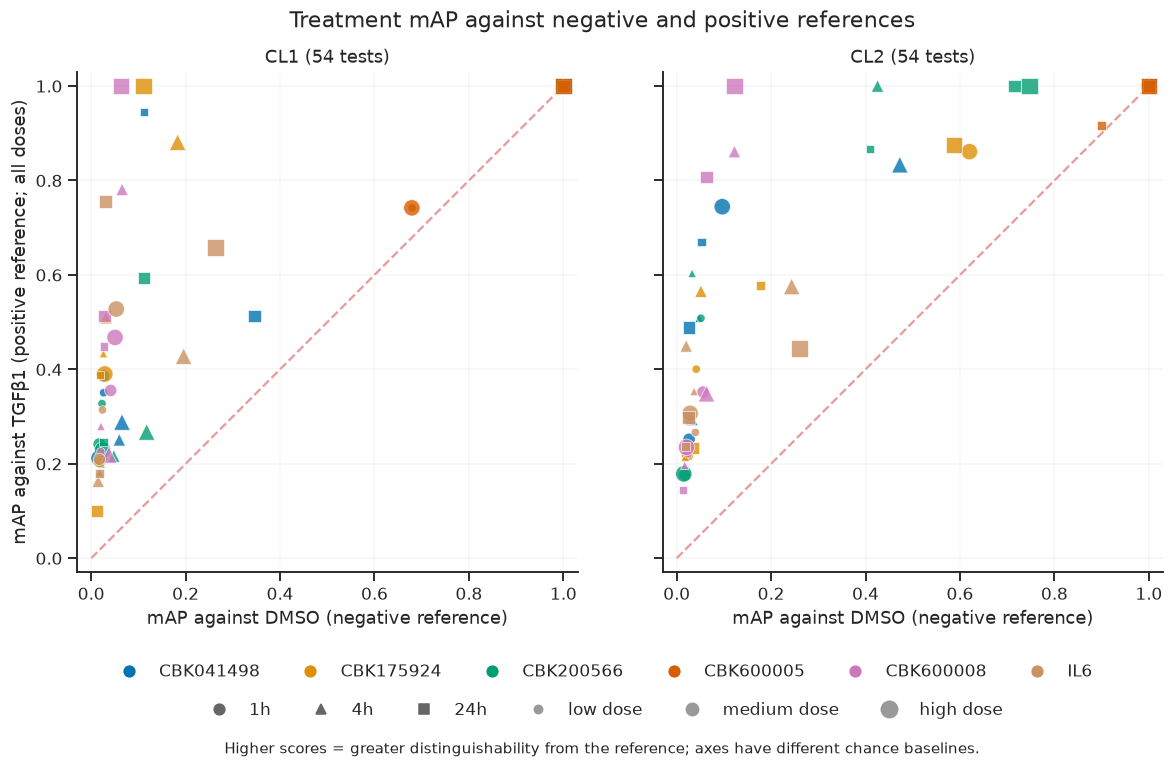

In [7]:
# Keep the original DMSO scores and calculate a separate TGFβ1-reference result.
# A boolean reference column lets mantispy use TGFβ1 without changing control labels.
positive_reference_data = map_data[
    (map_data.obs["Metadata_Perturbation"].astype(str) != "DMSO").to_numpy()
].copy()
positive_reference_data.obs["Metadata_TGFb1_reference"] = (
    positive_reference_data.obs["Metadata_Perturbation"].astype(str).str.startswith("TGFb1_").to_numpy()
)

# The positive reference is only used for the mAP calculation, not for the null distribution.
mt.tl.map(
    positive_reference_data, mode="activity", label="Metadata_query", batch="Metadata_panel",
    reference="Metadata_TGFb1_reference", distance="cosine", null_size=100_000,
    seed=seed, n_jobs=n_threads, key_added="map_vs_TGFb1",
)
positive_reference_scores = read_map(
    positive_reference_data.uns["mantispy"]["map_vs_TGFb1"]
).with_columns(pl.col("time_point").cast(pl.Enum(plate_order))).rename({
    "mAP": "mAP_vs_TGFb1", "mAP_pvalue": "mAP_vs_TGFb1_pvalue", "mAP_qvalue": "mAP_vs_TGFb1_qvalue",
})

# Count the number of reference wells for each plate and cell line, to report how many wells were used for each reference score.
reference_counts = (
    meta.group_by("Metadata_time_point", "Metadata_cell_line")
    .agg(
        (pl.col("agent") == "DMSO").sum().alias("n_DMSO_reference_wells"),
        (pl.col("agent") == "TGFb1").sum().alias("n_TGFb1_reference_wells"),
    )
    .rename({"Metadata_time_point": "time_point", "Metadata_cell_line": "cell_line"})
)

# Combine the two reference scores into one table, for plotting and reporting.
control_reference_scores = (
    scores.filter(pl.col("agent") != "TGFb1")
    .select(
        "time_point", "cell_line", "perturbation", "agent", "dose", "dose_level", "n_wells", "wells",
        pl.col("mAP").alias("mAP_vs_DMSO"),
        pl.col("mAP_pvalue").alias("mAP_vs_DMSO_pvalue"),
        pl.col("mAP_qvalue").alias("mAP_vs_DMSO_qvalue"),
    )
    .join(positive_reference_scores, on=["time_point", "cell_line", "perturbation"], how="left", validate="1:1")
    .join(reference_counts, on=["time_point", "cell_line"], how="left", validate="m:1")
    .sort("cell_line", "time_point", "agent", "dose_level")
)

# Check that all 108 compound/IL6 treatments have both reference scores, and save the table for reporting.
if control_reference_scores.height != 108 or control_reference_scores.select(
    pl.col("mAP_vs_DMSO", "mAP_vs_TGFb1").is_null().any()
).row(0) != (False, False):
    raise ValueError("Expected both reference scores for all 108 compound/IL6 tests")

# Save the table for reporting.
control_reference_scores.write_csv(table_dir / "map_control_references.csv")
print(f"Paired reference scores: {control_reference_scores.height} treatment × dose × time × cell-line tests")

# Plot the mAP scores against the negative and positive references, for each cell line and time point.
query_agents = [agent for agent in agent_order if agent != "TGFb1"]
reference_agent_colors = dict(zip(query_agents, sns.color_palette("colorblind", len(query_agents))))
time_markers = {"1h": "o", "4h": "^", "24h": "s"}
reference_dose_sizes = [30, 65, 115]

# The two reference scores are plotted against each other, with the negative reference on the x-axis and the positive reference on the y-axis.
# iterate over the two cell lines, and for each cell line iterate over the three time points, plotting the mAP scores for each treatment.
fig, axes = plt.subplots(1, 2, figsize=(13, 7), sharex=True, sharey=True)
for ax, line in zip(axes, line_order):
    sub = control_reference_scores.filter(pl.col("cell_line") == line)
    for agent in query_agents:
        for time in plate_order:
            points = sub.filter((pl.col("agent") == agent) & (pl.col("time_point") == time))
            
            # plot the points for this agent and time point, with the color for the agent, 
            # the marker for the time point, and the size for the dose level
            ax.scatter(
                points["mAP_vs_DMSO"].to_numpy(), points["mAP_vs_TGFb1"].to_numpy(),
                c=[reference_agent_colors[agent]], marker=time_markers[time],
                s=[reference_dose_sizes[level] for level in points["dose_level"]],
                alpha=0.8, edgecolors="white", linewidths=0.5,
            )
    
    # setting the title, axis labels, limits, aspect ratio, and grid for the subplot
    ax.set(title=f"{line} ({sub.height} tests)", xlabel="mAP against DMSO (negative reference)",
           xlim=(-0.03, 1.03), ylim=(-0.03, 1.03))
    ax.set_aspect("equal", adjustable="box")
    ax.grid(alpha=0.18)

# Add a label to the y-axis of the left subplot, since both subplots share the same y-axis.
axes[0].set_ylabel("mAP against TGFβ1 (positive reference; all doses)")

# creating legend handles for the agents, time points, and dose sizes
agent_handles = [
    Line2D([], [], marker="o", ls="", color=reference_agent_colors[agent], markersize=7, label=agent)
    for agent in query_agents
]
time_handles = [
    Line2D([], [], marker=time_markers[time], ls="", color="#666666", markersize=7, label=time)
    for time in plate_order
]
dose_handles = [
    Line2D([], [], marker="o", ls="", color="#999999", markersize=np.sqrt(size), label=label)
    for size, label in zip(reference_dose_sizes, ["low dose", "medium dose", "high dose"])
]

# add a red diagonal line to indicate equal mAP against both references
for ax in axes:
    ax.plot([0, 1], [0, 1], ls="--", color="#d03b3b", alpha=0.5, zorder=0)

# set legend 
fig.legend(handles=agent_handles, loc="lower center", bbox_to_anchor=(0.5, 0.09), ncol=6, frameon=False)
fig.legend(handles=time_handles + dose_handles, loc="lower center", bbox_to_anchor=(0.5, 0.04), ncol=6, frameon=False)

# set title 
fig.suptitle("Treatment mAP against negative and positive references", y=0.98)

# add a note about the interpretation of the axes
fig.text(0.5, 0.015, "Higher scores = greater distinguishability from the reference; axes have different chance baselines.",
         ha="center", fontsize=10)

# adjust the subplots to make room for the legends and title
fig.subplots_adjust(bottom=0.25, top=0.9, wspace=0.12)

save_figure(fig, "02b_map-negative-vs-positive-reference")


In [8]:
# one summary row per plate and cell line
panel_summary = []
for time, line in panels:
    sub = scores.filter((pl.col("time_point") == time) & (pl.col("cell_line") == line))
    fake_sub = fake_scores.filter((pl.col("time_point") == time) & (pl.col("cell_line") == line))
    panel_summary.append({
        "time_point": time, "cell_line": line, "treatments": sub.height, "treatments_with_3_wells": int((sub["n_wells"] == 3).sum()),
        "corr_threshold": corr_thresholds[(time, line)],
        "percent_replicating": 100 * sub["replicating"].mean(),
        "dmso_sets_passing_corr_pct": 100 * (dmso_scores[(time, line)] > corr_thresholds[(time, line)]).mean(),
        "percent_active_mAP": 100 * sub["active"].mean(),
        "fake_dmso_p05_pct": 100 * (fake_sub["mAP_pvalue"] < 0.05).mean(),
    })
panel_summary = pl.DataFrame(panel_summary)
panel_summary.write_csv(table_dir / "panel_summary.csv")
print(panel_summary.with_columns(pl.selectors.float().round(1)))

shape: (6, 9)
┌───────────┬───────────┬───────────┬───────────┬───┬───────────┬───────────┬───────────┬──────────┐
│ time_poin ┆ cell_line ┆ treatment ┆ treatment ┆ … ┆ percent_r ┆ dmso_sets ┆ percent_a ┆ fake_dms │
│ t         ┆ ---       ┆ s         ┆ s_with_3_ ┆   ┆ eplicatin ┆ _passing_ ┆ ctive_mAP ┆ o_p05_pc │
│ ---       ┆ str       ┆ ---       ┆ wells     ┆   ┆ g         ┆ corr_pct  ┆ ---       ┆ t        │
│ str       ┆           ┆ i64       ┆ ---       ┆   ┆ ---       ┆ ---       ┆ f64       ┆ ---      │
│           ┆           ┆           ┆ i64       ┆   ┆ f64       ┆ f64       ┆           ┆ f64      │
╞═══════════╪═══════════╪═══════════╪═══════════╪═══╪═══════════╪═══════════╪═══════════╪══════════╡
│ 1h        ┆ CL1       ┆ 21        ┆ 21        ┆ … ┆ 19.0      ┆ 4.9       ┆ 14.3      ┆ 0.0      │
│ 1h        ┆ CL2       ┆ 21        ┆ 21        ┆ … ┆ 19.0      ┆ 4.9       ┆ 19.0      ┆ 0.0      │
│ 4h        ┆ CL1       ┆ 21        ┆ 21        ┆ … ┆ 33.3      ┆ 4.6       ┆

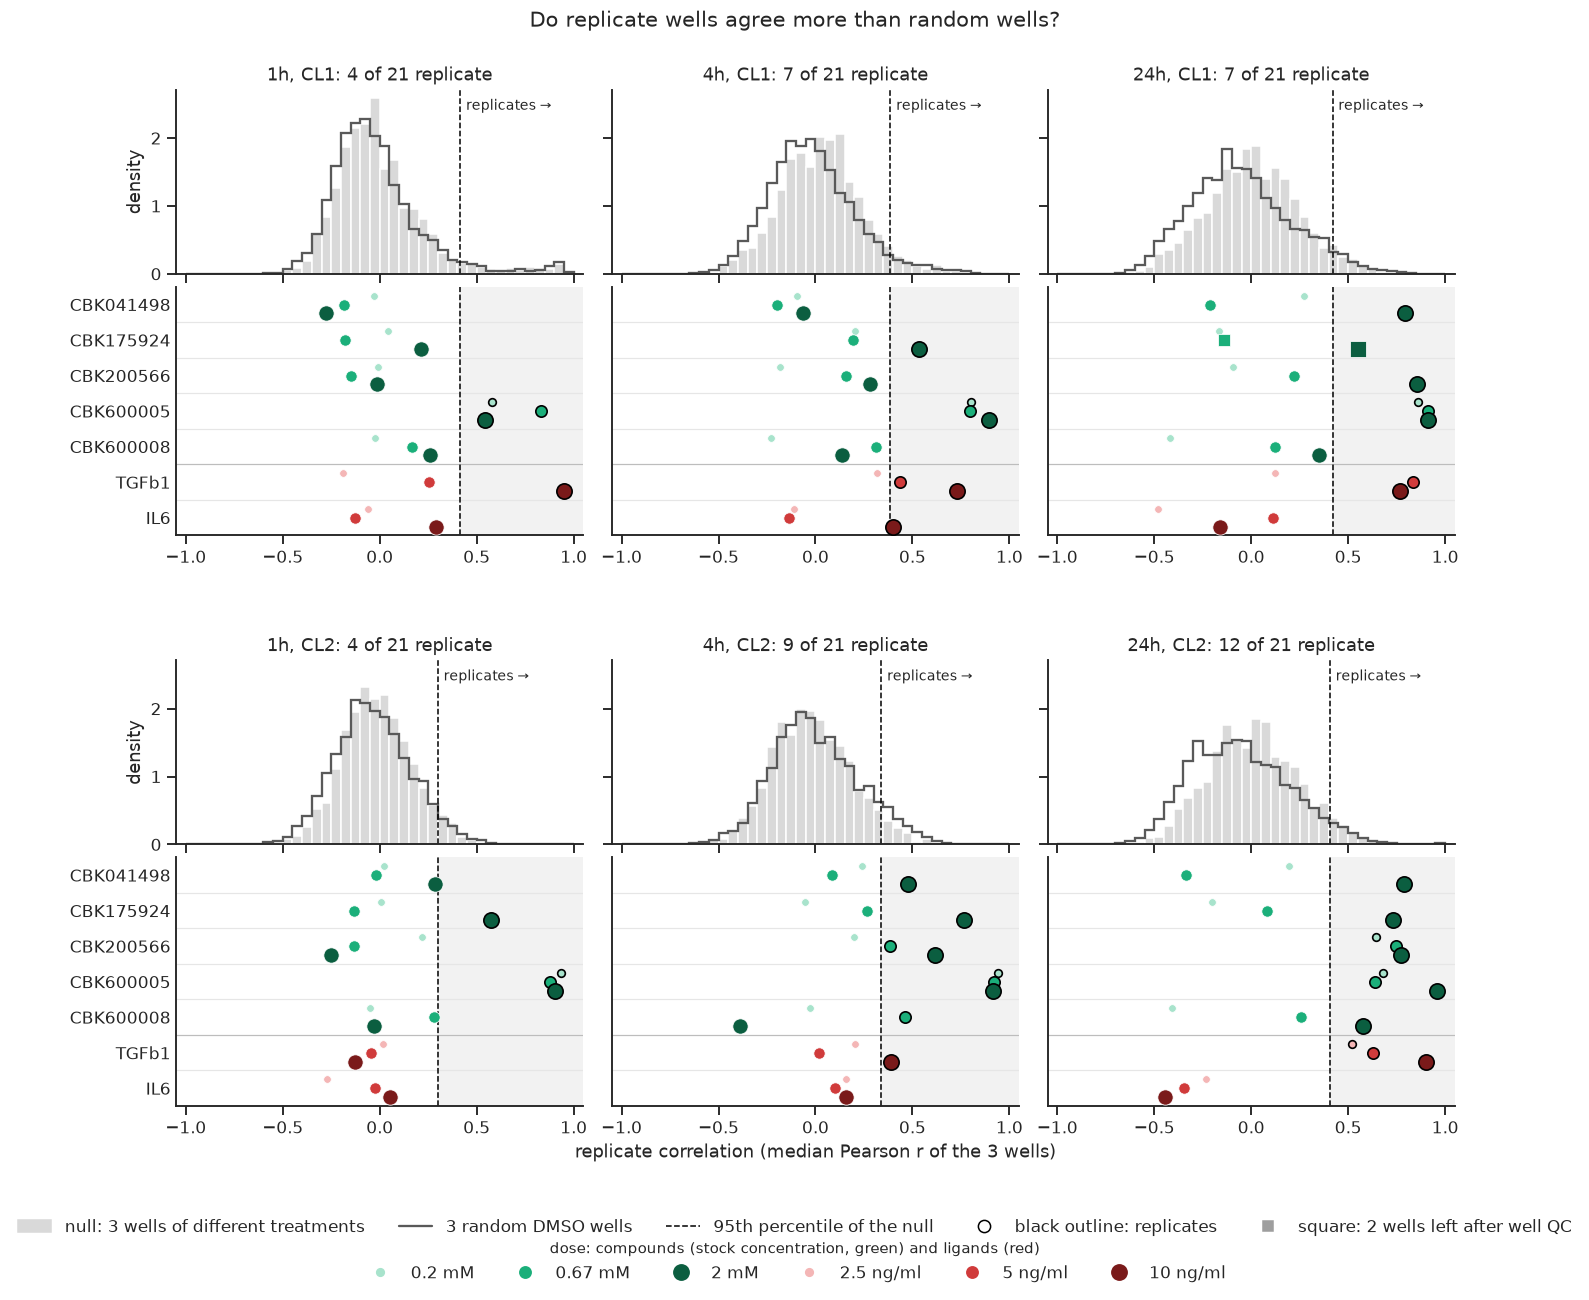

In [9]:
# figure: replicate correlation of each treatment against the null, per plate and cell line
# top of each panel: the null; below it: one row per agent, one dot per dose
dose_sizes = [25, 55, 100]
dose_shades = {"compound": ["#a8e3cc", "#1baf7a", "#0b5e40"], "ligand": ["#f4b6b6", "#d03b3b", "#7a1a1a"]}
# within an agent row, low dose sits on top and high dose at the bottom
dose_offsets = [-0.25, 0.0, 0.25]
bins = np.linspace(-1, 1, 41)
fig = plt.figure(figsize=(15, 12))
outer = fig.add_gridspec(2, 3, hspace=0.28, wspace=0.07)
first_hist = first_dots = None
for j, time in enumerate(plate_order):
    for i, line in enumerate(line_order):
        inner = outer[i, j].subgridspec(2, 1, height_ratios=[1, 1.35], hspace=0.06)
        ax_hist = fig.add_subplot(inner[0], sharex=first_hist, sharey=first_hist)
        ax_dots = fig.add_subplot(inner[1], sharex=ax_hist, sharey=first_dots)
        first_hist, first_dots = first_hist or ax_hist, first_dots or ax_dots
        threshold = corr_thresholds[(time, line)]
        sub = scores.filter((pl.col("time_point") == time) & (pl.col("cell_line") == line))

        # top: the null, the DMSO check and the threshold
        ax_hist.hist(null_scores[(time, line)], bins=bins, density=True, color="#d9d9d9")
        ax_hist.hist(dmso_scores[(time, line)], bins=bins, density=True, histtype="step", color="#595959", lw=1.5)
        ax_hist.axvline(threshold, ls="--", color="black", lw=1)
        ax_hist.text(threshold + 0.03, 0.95, "replicates →", transform=ax_hist.get_xaxis_transform(), va="top", fontsize=9)
        ax_hist.set_title(f"{time}, {line}: {sub['replicating'].sum()} of {sub['replicating'].count()} replicate", fontsize=12)
        ax_hist.tick_params(labelbottom=False)
        if j == 0:
            ax_hist.set_ylabel("density")
        else:
            ax_hist.tick_params(labelleft=False)

        # bottom: one row per agent, one dot per dose
        ax_dots.axvspan(threshold, 1.05, color="#f2f2f2", zorder=0)
        ax_dots.axvline(threshold, ls="--", color="black", lw=1)
        for k in range(len(agent_order) - 1):
            ax_dots.axhline(k + 0.5, color="#bdbdbd" if agent_order[k + 1] in ligands and agent_order[k] not in ligands else "#e6e6e6", lw=0.8, zorder=1)
        for r in sub.filter(pl.col("replicate_corr").is_not_null()).iter_rows(named=True):
            level = r["dose_level"]
            ax_dots.scatter(
                r["replicate_corr"], agent_order.index(r["agent"]) + dose_offsets[level],
                s=dose_sizes[level], color=dose_shades[r["well_type"]][level], marker="o" if r["n_wells"] == 3 else "s",
                edgecolor="black" if r["replicating"] else "white", lw=1.1 if r["replicating"] else 0.5, zorder=3,
            )
        ax_dots.set_yticks(range(len(agent_order)), agent_order)
        ax_dots.set_ylim(len(agent_order) - 0.5, -0.5)
        ax_dots.tick_params(axis="y", length=0, labelleft=j == 0)
        ax_dots.set_xlim(-1.05, 1.05)
        if i == 1 and j == 1:
            ax_dots.set_xlabel("replicate correlation (median Pearson r of the 3 wells)", fontsize=12)

line_handles = [
    Patch(color="#d9d9d9", label="null: 3 wells of different treatments"),
    Line2D([], [], color="#595959", lw=1.5, label="3 random DMSO wells"),
    Line2D([], [], color="black", ls="--", lw=1, label="95th percentile of the null"),
    Line2D([], [], marker="o", ls="", markerfacecolor="white", markeredgecolor="black", markersize=8, label="black outline: replicates"),
]
if (scores["n_wells"] == 2).any():
    line_handles.append(Line2D([], [], marker="s", ls="", color="#9e9e9e", markersize=7, label="square: 2 wells left after well QC"))
dose_handles = [
    Line2D([], [], marker="o", ls="", color=dose_shades[kind][level], markersize=np.sqrt(dose_sizes[level]), label=dose_text[dose])
    for kind, doses in (("compound", ["0.2", "0.67", "2.0"]), ("ligand", ["L", "M", "H"]))
    for level, dose in enumerate(doses)
]
fig.legend(handles=line_handles, loc="lower center", ncol=len(line_handles), frameon=False, bbox_to_anchor=(0.5, 0.0))
fig.legend(
    handles=dose_handles, loc="lower center", ncol=6, frameon=False, bbox_to_anchor=(0.5, -0.035),
    title="dose: compounds (stock concentration, green) and ligands (red)", title_fontsize=10,
)
fig.suptitle("Do replicate wells agree more than random wells?", fontsize=14, y=0.94)
save_figure(fig, "01_replicate-correlation-vs-null")

In [10]:
# which doses replicate, per agent, plate and cell line ("–" = no dose)
panel_columns = [f"{time} {line}" for line in line_order for time in plate_order]
replicating_doses = (
    scores.sort("dose_level")
    .with_columns(
        (pl.col("time_point").cast(pl.Utf8) + " " + pl.col("cell_line")).alias("panel"),
        pl.col("dose").replace_strict(dose_text).alias("dose_text"),
    )
    .group_by("agent", "panel", maintain_order=True)
    .agg(pl.col("dose_text").filter(pl.col("replicating").fill_null(False)).str.join(", ").alias("doses"))
    .with_columns(pl.when(pl.col("doses") == "").then(pl.lit("–")).otherwise(pl.col("doses")).alias("doses"))
    .pivot(on="panel", index="agent", values="doses")
    .select("agent", *panel_columns)
    .sort(pl.col("agent").replace_strict({a: i for i, a in enumerate(agent_order)}))
)
replicating_doses.write_csv(table_dir / "replicating_doses.csv")
with pl.Config(tbl_rows=100, tbl_width_chars=250, fmt_str_lengths=40, tbl_hide_dataframe_shape=True, tbl_hide_column_data_types=True):
    print(replicating_doses)
    # the wells behind each replicating treatment
    print(
        scores.filter(pl.col("replicating"))
        .sort("cell_line", "time_point", pl.col("perturbation").replace_strict({p: i for i, p in enumerate(perturbation_order)}))
        .select(
            "time_point", "cell_line", pl.col("perturbation").map_elements(pretty, return_dtype=pl.Utf8).alias("treatment"),
            pl.col("replicate_corr").round(2), pl.col("corr_threshold").round(2), "wells",
        )
    )

┌───────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬──────────────────────────────┐
│ agent     ┆ 1h CL1                ┆ 4h CL1                ┆ 24h CL1               ┆ 1h CL2                ┆ 4h CL2                ┆ 24h CL2                      │
╞═══════════╪═══════════════════════╪═══════════════════════╪═══════════════════════╪═══════════════════════╪═══════════════════════╪══════════════════════════════╡
│ CBK041498 ┆ –                     ┆ –                     ┆ 2 mM                  ┆ –                     ┆ 2 mM                  ┆ 2 mM                         │
│ CBK175924 ┆ –                     ┆ 2 mM                  ┆ –                     ┆ 2 mM                  ┆ 2 mM                  ┆ 2 mM                         │
│ CBK200566 ┆ –                     ┆ –                     ┆ 2 mM                  ┆ –                     ┆ 0.67 mM, 2 mM         ┆ 0.2 mM, 0.67 mM, 2 mM        │
│ CBK60000

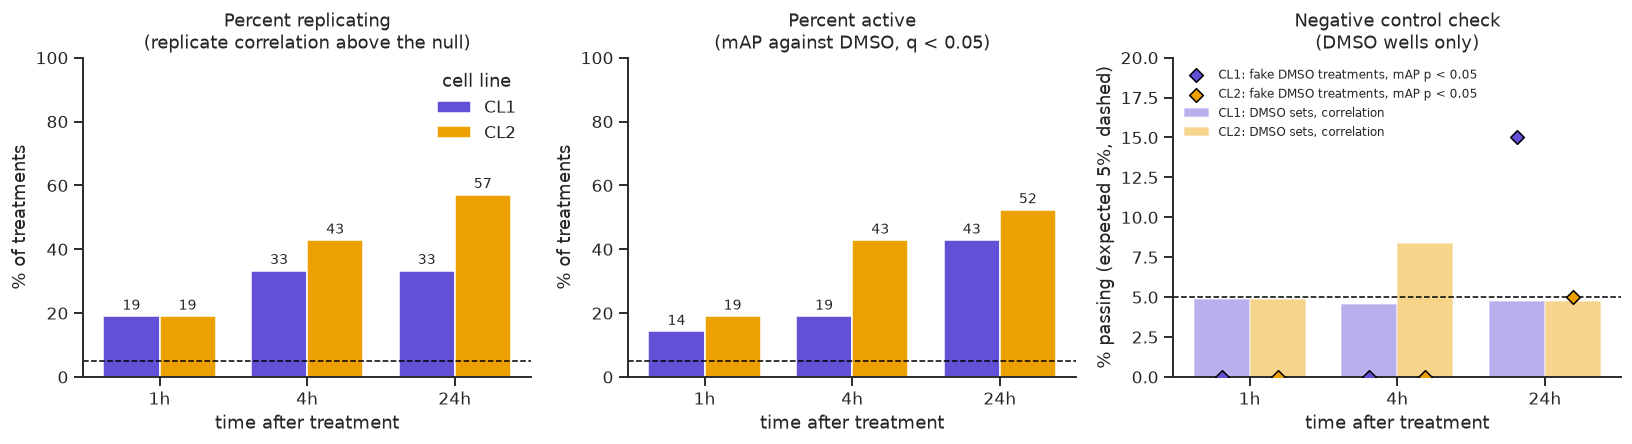

In [11]:
# figure: summary of reproducibility and activity, with the DMSO checks
summary_pd = panel_summary.to_pandas()
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
x = np.arange(len(plate_order))
width = 0.38
for k, line in enumerate(line_order):
    sub = summary_pd[summary_pd["cell_line"] == line].set_index("time_point").loc[plate_order]
    offset = (k - 0.5) * width
    axes[0].bar(x + offset, sub["percent_replicating"], width, color=line_colors[line], label=line)
    axes[1].bar(x + offset, sub["percent_active_mAP"], width, color=line_colors[line], label=line)
    axes[2].bar(x + offset, sub["dmso_sets_passing_corr_pct"], width, color=line_colors[line], alpha=0.45, label=f"{line}: DMSO sets, correlation")
    axes[2].scatter(x + offset, sub["fake_dmso_p05_pct"], marker="D", s=40, color=line_colors[line], edgecolor="black", zorder=3, label=f"{line}: fake DMSO treatments, mAP p < 0.05")
    for ax, column in zip(axes[:2], ["percent_replicating", "percent_active_mAP"]):
        for xi, value in zip(x + offset, sub[column]):
            ax.text(xi, value + 1, f"{value:.0f}", ha="center", va="bottom", fontsize=9)
titles = [
    "Percent replicating\n(replicate correlation above the null)",
    "Percent active\n(mAP against DMSO, q < 0.05)",
    "Negative control check\n(DMSO wells only)",
]
for ax, title in zip(axes, titles):
    ax.set_xticks(x, plate_order)
    ax.set_xlabel("time after treatment")
    ax.set_title(title, fontsize=12)
    ax.axhline(5, ls="--", color="black", lw=1)
axes[0].set_ylabel("% of treatments")
axes[1].set_ylabel("% of treatments")
axes[2].set_ylabel("% passing (expected 5%, dashed)")
axes[0].set_ylim(0, 100)
axes[1].set_ylim(0, 100)
axes[2].set_ylim(0, 20)
axes[0].legend(frameon=False, title="cell line")
axes[2].legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout()
save_figure(fig, "02_reproducibility-summary")

**Result:**

- Percent replicating rises with time: 19% (4 of 21) in both cell lines at 1h, 33% (CL1) and 43% (CL2) at 4h, 33% (CL1) and 57% (CL2) at 24h; 43 of 126 tests (34%) overall.
- mAP calls 40 of 126 tests active: 14% / 19% at 1h, 19% / 43% at 4h, 43% / 52% at 24h (CL1 / CL2). The two readouts mostly agree: 6 tests replicate without being active, and 3 are active without replicating.
- The DMSO controls behave as expected: random DMSO sets pass the correlation threshold 4.6–4.9% of the time (8.4% in CL2 at 4h), and 4 of 120 fake DMSO treatments (3.3%) have mAP p < 0.05, none q < 0.05. 3 of these 4 are in CL1 at 24h, the plate with uneven cell numbers.
- **Doses:** CBK600005 replicates at all 3 doses on every plate. CBK041498, CBK175924 and CBK600008 replicate only at 2 mM. CBK200566 (CL2, 4h and 24h) and TGFβ1 (CL2, 24h) also replicate at lower doses. The full list, with the 3 wells of each set, is above and in `replicating_doses.csv`.
- CBK175924 2 mM in CL1 at 24h lost a well to well QC; its 2 remaining wells (r = 0.55) fall just below the stricter threshold for 2 wells (0.61).
- TGFβ1 10 ng/ml has the highest score in CL1 at 1h (r = 0.95), but its 3 wells (C02, E01, E06) lie in odd rows of columns 1–6, the shifted area of section 3a: this is most likely the plate effect, not TGFβ1.

## 3. Replicate health

### 3a. Are the DMSO wells alike across the plate?

DMSO wells should all look alike, wherever they sit on the plate. For each well we measure its distance from the DMSO centre (the Euclidean distance of its rescaled profile from the median DMSO well). A DMSO well is **unusual** when its distance is above the median + 3 MAD of all DMSO wells of that plate and cell line. The plate maps show every well; unusual DMSO wells have a black frame.

**Pass if:** unusual DMSO wells are few and scattered, not grouped in one area of the plate.

In [12]:
dmso_rows, unusual_profile, distance_limits = [], {}, {}
for time, line in panels:
    dmso = meta.filter(panel_filter(time, line) & (pl.col("agent") == "DMSO"))
    d = dmso["distance"].to_numpy()
    limit = np.median(d) + unusual_mads * 1.4826 * np.median(np.abs(d - np.median(d)))
    distance_limits[(time, line)] = limit
    unusual = dmso.filter(pl.col("distance") > limit)
    normal = dmso.filter(pl.col("distance") <= limit)
    # the shared profile of the unusual DMSO wells, used to spot treatments that look like them
    unusual_profile[(time, line)] = np.median(profiles[unusual["row"].to_numpy()], axis=0) if unusual.height >= 3 else None
    in_odd_rows = unusual.filter(pl.col("Metadata_Row").is_in(list("ACEGIKMO"))).height
    corr_unusual = np.corrcoef(profiles[unusual["row"].to_numpy()]) if unusual.height >= 3 else None
    dmso_rows.append({
        "time_point": time, "cell_line": line, "dmso_wells": dmso.height, "unusual_wells": unusual.height,
        "unusual_in_odd_rows": in_odd_rows,
        "unusual_columns": ", ".join(sorted(unusual["Metadata_Column"].unique().to_list())),
        "distance_limit": limit,
        "median_cells_unusual": unusual["Metadata_CellCount"].median(),
        "median_cells_normal": normal["Metadata_CellCount"].median(),
        "median_corr_among_unusual": np.median(corr_unusual[np.triu_indices(unusual.height, 1)]) if corr_unusual is not None else None,
    })
dmso_health = pl.DataFrame(dmso_rows)
dmso_health.write_csv(table_dir / "dmso_well_health.csv")
with pl.Config(tbl_width_chars=200, tbl_cols=20, fmt_str_lengths=60):
    print(dmso_health.with_columns(pl.selectors.float().round(2)))

shape: (6, 10)
┌────────────┬───────────┬────────────┬───────────────┬─────────────────────┬─────────────────────────────┬────────────────┬──────────────────────┬─────────────────────┬───────────────────────────┐
│ time_point ┆ cell_line ┆ dmso_wells ┆ unusual_wells ┆ unusual_in_odd_rows ┆ unusual_columns             ┆ distance_limit ┆ median_cells_unusual ┆ median_cells_normal ┆ median_corr_among_unusual │
│ ---        ┆ ---       ┆ ---        ┆ ---           ┆ ---                 ┆ ---                         ┆ ---            ┆ ---                  ┆ ---                 ┆ ---                       │
│ str        ┆ str       ┆ i64        ┆ i64           ┆ i64                 ┆ str                         ┆ f64            ┆ f64                  ┆ f64                 ┆ f64                       │
╞════════════╪═══════════╪════════════╪═══════════════╪═════════════════════╪═════════════════════════════╪════════════════╪══════════════════════╪═════════════════════╪════════════════════════

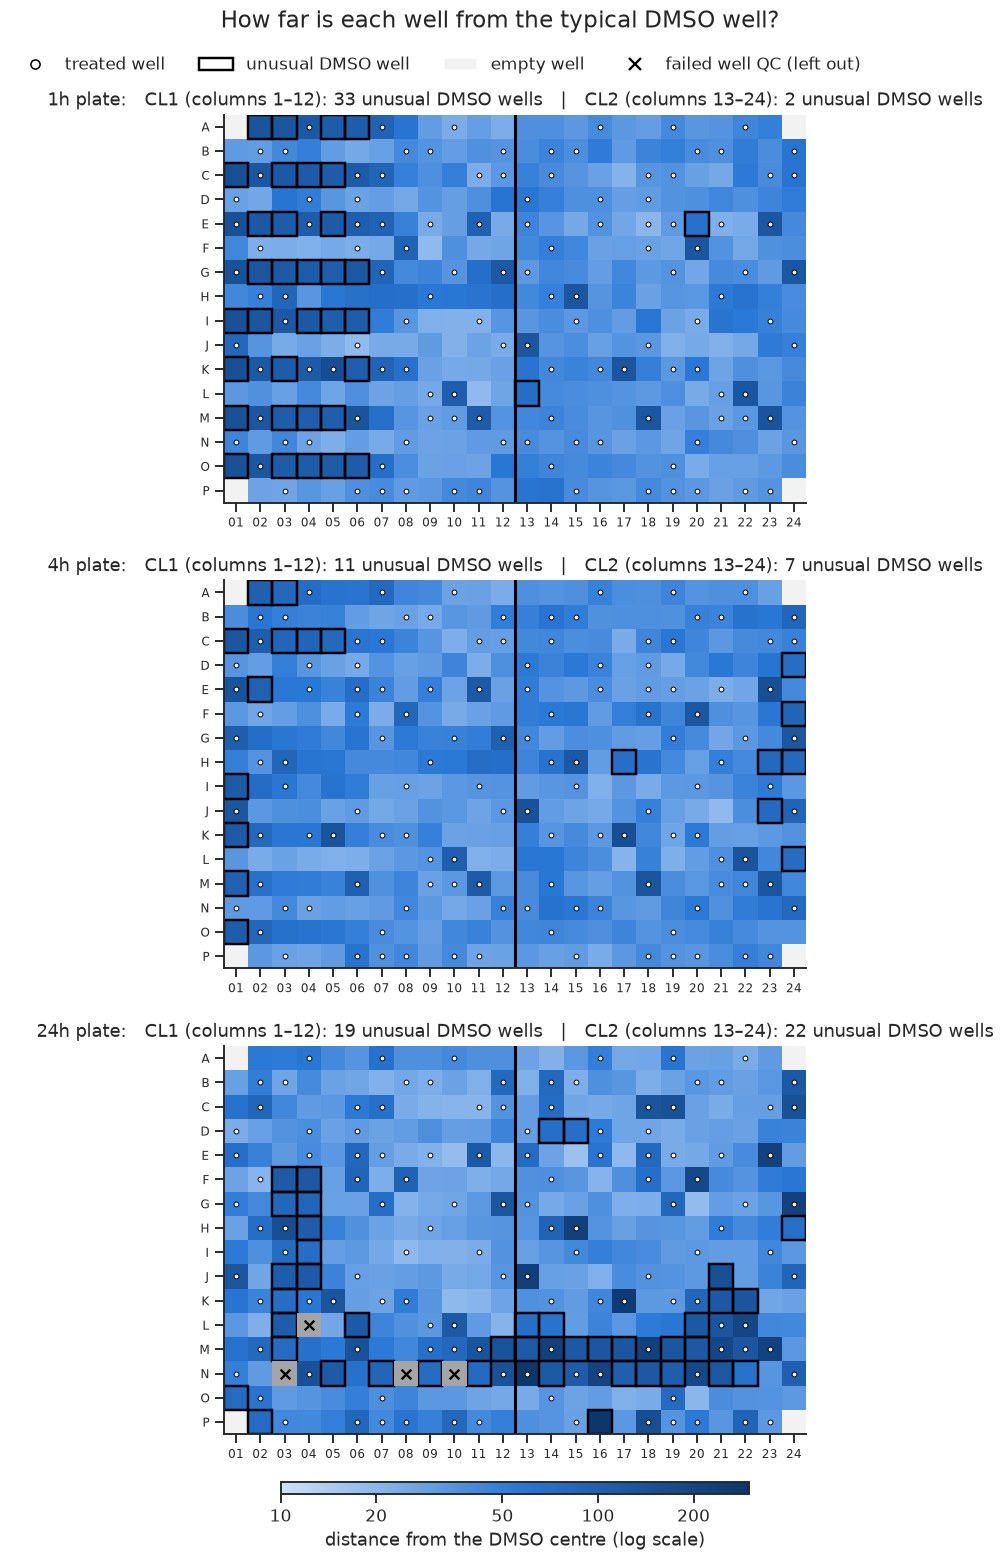

In [13]:
# figure: plate maps of the distance of every well from the DMSO centre
row_letters = list("ABCDEFGHIJKLMNOP")
fig, axes = plt.subplots(3, 1, figsize=(11, 19))
norm = LogNorm(vmin=10, vmax=300)
cmap = blues.copy()
cmap.set_bad("#f2f2f2")
for ax, time in zip(axes, plate_order):
    plate = meta.filter(pl.col("Metadata_time_point") == time)
    grid = np.full((16, 24), np.nan)
    r_idx = np.array([row_letters.index(r) for r in plate["Metadata_Row"]])
    c_idx = plate["Metadata_Column"].cast(pl.Int64).to_numpy() - 1
    grid[r_idx, c_idx] = plate["distance"].to_numpy()
    image = ax.imshow(grid, cmap=cmap, norm=norm, aspect="equal")
    treated = (plate["agent"] != "DMSO").to_numpy()
    ax.scatter(c_idx[treated], r_idx[treated], s=10, color="white", edgecolor="black", lw=0.6)
    limits = np.array([distance_limits[(time, line)] for line in plate["Metadata_cell_line"]])
    unusual = (~treated) & (plate["distance"].to_numpy() > limits)
    for r, c in zip(r_idx[unusual], c_idx[unusual]):
        ax.add_patch(Rectangle((c - 0.5, r - 0.5), 1, 1, fill=False, edgecolor="black", lw=1.6))
    # wells that failed well QC: grey with a cross
    failed = failed_wells.filter(pl.col("Metadata_time_point") == time)
    for r, c in zip(failed["Metadata_Row"], failed["Metadata_Column"].cast(pl.Int64)):
        ax.add_patch(Rectangle((c - 1.5, row_letters.index(r) - 0.5), 1, 1, facecolor="#a5a5a5", edgecolor="none"))
        ax.scatter(c - 1, row_letters.index(r), marker="x", s=40, color="black", lw=1.5)
    ax.axvline(11.5, color="black", lw=2)
    ax.set_xticks(range(24), [f"{c:02d}" for c in range(1, 25)], fontsize=8)
    ax.set_yticks(range(16), row_letters, fontsize=8)
    n_unusual = {line: dmso_health.filter((pl.col("time_point") == time) & (pl.col("cell_line") == line))["unusual_wells"].item() for line in line_order}
    ax.set_title(
        f"{time} plate:   CL1 (columns 1–12): {n_unusual['CL1']} unusual DMSO wells   |   CL2 (columns 13–24): {n_unusual['CL2']} unusual DMSO wells",
        fontsize=12,
    )
cbar = fig.colorbar(image, ax=axes, location="bottom", shrink=0.5, pad=0.03, aspect=40)
cbar.set_ticks([10, 20, 50, 100, 200], labels=["10", "20", "50", "100", "200"])
cbar.minorticks_off()
cbar.set_label("distance from the DMSO centre (log scale)")
handles = [
    Line2D([], [], marker="o", ls="", markerfacecolor="white", markeredgecolor="black", label="treated well"),
    Patch(facecolor="none", edgecolor="black", lw=1.6, label="unusual DMSO well"),
    Patch(facecolor="#f2f2f2", label="empty well"),
    Line2D([], [], marker="x", ls="", color="black", markerfacecolor="#a5a5a5", markersize=8, markeredgewidth=1.5, label="failed well QC (left out)"),
]
fig.legend(handles=handles, loc="upper center", ncol=4, frameon=False, bbox_to_anchor=(0.45, 0.915))
fig.suptitle("How far is each well from the typical DMSO well?", fontsize=15, y=0.93)
save_figure(fig, "03_plate-maps-distance-from-dmso")

**Result:**

- The DMSO wells are not uniform. In CL1 at 1h, 33 of 127 DMSO wells (26%) are unusual, all in the odd rows (A, C, …, O) of columns 1–6. They share one profile (median r = 0.91 between them) and have slightly fewer cells (1,722 vs 1,902). The same pattern is weaker at 4h (11 wells, odd rows, columns 1–5) and gone at 24h. A pattern that follows every other row looks technical (liquid handling, plate handling or imaging), not biological.
- At 24h, unusual DMSO wells form a band in rows M–N across both cell lines, a block in columns 3–4 (rows F–M) in CL1, and a group in columns 20–22 (rows J–N) in CL2: 19 wells in CL1 and 22 in CL2. They have fewer cells: median 319 vs 1,670 in CL1, and 2,546 vs 3,251 in CL2. The 2 emptiest DMSO wells of CL1 (L04, N10) already failed well QC.
- CL2 at 1h and 4h is nearly clean (2 and 7 unusual DMSO wells; at 4h mostly at the right edge, columns 23–24).
- Treated wells in these areas inherit the shift, so a treatment can look active only because of where its wells sit. Below we flag treatments and wells that correlate r ≥ 0.8 with the shared profile of the unusual DMSO wells.

### 3b. Outlier replicates

For each treatment with 3 wells, we check whether one of them disagrees with the other two. A well is an **outlier replicate** when:

- **direction:** its two siblings correlate with each other above chance, but it correlates with neither of them above chance (chance = 95th percentile of the correlation between two wells of different treatments), or
- **strength:** it lies outside the normal DMSO range (distance limit of 3a) while both siblings lie inside it, or the reverse.

We also give each well's cell count, its plate position, and its correlation with the unusual DMSO wells of 3a ("looks like unusual DMSO" when r ≥ 0.8), which helps to tell a technical problem from biology.

In [14]:
health_rows = []
for time, line in panels:
    panel = meta.filter(panel_filter(time, line))
    rows = panel["row"].to_numpy()
    corr = np.corrcoef(profiles[rows])
    labels = panel["Metadata_Perturbation"].to_numpy()
    wells_of = {p: np.flatnonzero(labels == p) for p in np.unique(labels)}
    groups = list(wells_of)
    # chance level for one pair: two wells of two different perturbations
    pair_null = np.array([corr[rng.choice(wells_of[a]), rng.choice(wells_of[b])] for a, b in (rng.choice(groups, 2, replace=False) for _ in range(n_null))])
    pair_limit = np.quantile(pair_null, null_quantile)
    distance = panel["distance"].to_numpy()
    far = distance > distance_limits[(time, line)]
    cells = panel["Metadata_CellCount"].to_numpy()
    artifact = unusual_profile[(time, line)]
    like_unusual = [float(np.corrcoef(profiles[r], artifact)[0, 1]) for r in rows] if artifact is not None else [None] * len(rows)
    dmso_cells = np.median(cells[wells_of["DMSO"]])

    for perturbation in groups:
        if perturbation == "DMSO":
            continue
        trio = wells_of[perturbation]
        # the outlier rules need 3 wells
        if len(trio) != 3:
            continue
        for k, w in enumerate(trio):
            s1, s2 = np.delete(trio, k)
            own = (corr[w, s1], corr[w, s2])
            disagrees = corr[s1, s2] > pair_limit and max(own) < pair_limit
            odd_strength = far[w] != far[s1] and far[s1] == far[s2]
            reason = "; ".join(
                text for flag, text in [
                    (disagrees, "direction: siblings agree, this well does not"),
                    (odd_strength and far[w], "strength: only this well is outside the DMSO range"),
                    (odd_strength and not far[w], "strength: only this well is inside the DMSO range"),
                ] if flag
            )
            health_rows.append({
                "time_point": time, "cell_line": line, "perturbation": perturbation,
                "well": panel["Metadata_Well"][int(w)],
                "sibling_wells": ", ".join(panel["Metadata_Well"][int(s)] for s in (s1, s2)),
                "corr_with_siblings": float(np.mean(own)), "corr_between_siblings": float(corr[s1, s2]), "pair_chance_limit": float(pair_limit),
                "distance": float(distance[w]), "sibling_distances": f"{distance[s1]:.0f}, {distance[s2]:.0f}",
                "dmso_distance_limit": float(distance_limits[(time, line)]),
                "cells": int(cells[w]), "sibling_cells": f"{cells[s1]}, {cells[s2]}", "dmso_median_cells": float(dmso_cells),
                "corr_with_unusual_dmso": like_unusual[w],
                "outlier": bool(disagrees or odd_strength), "reason": reason,
            })

health = pl.DataFrame(health_rows).with_columns(pl.col("time_point").cast(pl.Enum(plate_order)))
outliers = health.filter(pl.col("outlier")).sort("time_point", "cell_line", "perturbation")
outliers.write_csv(table_dir / "outlier_replicates.csv")
health.write_csv(table_dir / "replicate_well_health.csv")

sets_with_outlier = outliers.select("time_point", "cell_line", "perturbation").unique().height
print(f"outlier replicate wells: {outliers.height} of {health.height} treated wells in sets of 3; replicate sets with an outlier: {sets_with_outlier} of {scores.filter(pl.col('n_wells') == 3).height}")
print(outliers.group_by("time_point", "cell_line").len().sort("time_point", "cell_line"))
print(f"outliers that look like unusual DMSO wells (r >= {artifact_corr}): {(outliers['corr_with_unusual_dmso'] >= artifact_corr).fill_null(False).sum()}")
with pl.Config(tbl_rows=100, tbl_width_chars=250, tbl_cols=20, fmt_str_lengths=60):
    print(
        outliers.select(
            "time_point", "cell_line", "perturbation", "well", "sibling_wells",
            pl.col("corr_with_siblings").round(2), pl.col("corr_between_siblings").round(2),
            pl.col("distance").round(0), "sibling_distances", "cells", "sibling_cells",
            pl.col("corr_with_unusual_dmso").round(2), "reason",
        )
    )

outlier replicate wells: 48 of 372 treated wells in sets of 3; replicate sets with an outlier: 46 of 124
shape: (6, 3)
┌────────────┬───────────┬─────┐
│ time_point ┆ cell_line ┆ len │
│ ---        ┆ ---       ┆ --- │
│ enum       ┆ str       ┆ u32 │
╞════════════╪═══════════╪═════╡
│ 1h         ┆ CL1       ┆ 15  │
│ 1h         ┆ CL2       ┆ 1   │
│ 4h         ┆ CL1       ┆ 7   │
│ 4h         ┆ CL2       ┆ 10  │
│ 24h        ┆ CL1       ┆ 7   │
│ 24h        ┆ CL2       ┆ 8   │
└────────────┴───────────┴─────┘
outliers that look like unusual DMSO wells (r >= 0.8): 17
shape: (48, 13)
┌────────────┬───────────┬────────────────┬──────┬───────────────┬────────────────────┬───────────────────────┬──────────┬───────────────────┬───────┬───────────────┬────────────────────────┬──────────────────────────────────────────────────────────┐
│ time_point ┆ cell_line ┆ perturbation   ┆ well ┆ sibling_wells ┆ corr_with_siblings ┆ corr_between_siblings ┆ distance ┆ sibling_distances ┆ cells ┆ sibling_c

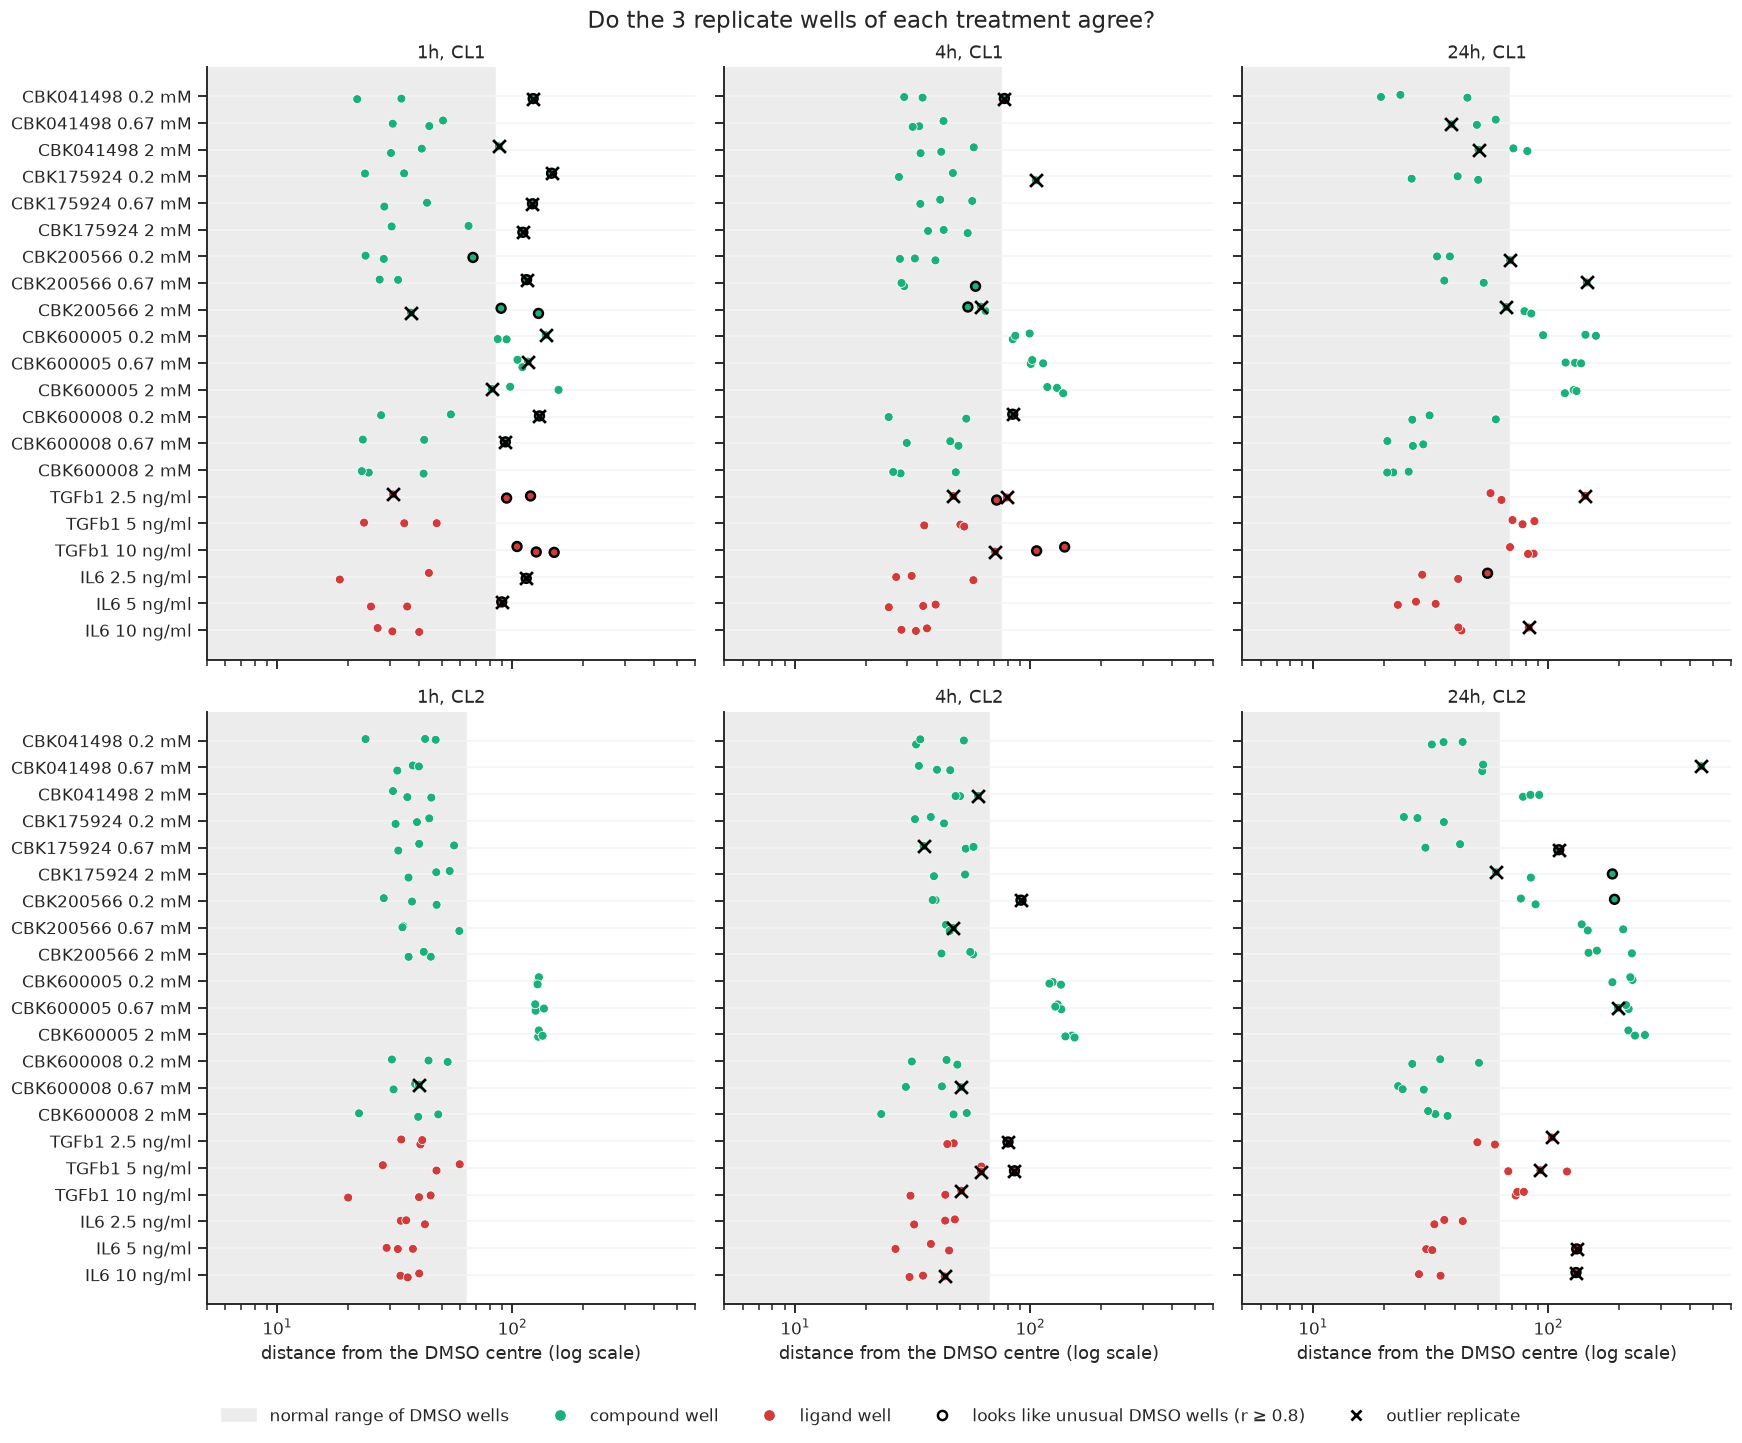

In [15]:
# figure: the 3 replicate wells of each treatment, by distance from the DMSO centre
fig, axes = plt.subplots(2, 3, figsize=(16, 13), sharey=True, sharex=True)
y_of = {p: i for i, p in enumerate(perturbation_order)}
for j, time in enumerate(plate_order):
    for i, line in enumerate(line_order):
        ax = axes[i, j]
        sub = health.filter((pl.col("time_point") == time) & (pl.col("cell_line") == line))
        ax.axvspan(5, distance_limits[(time, line)], color="#ececec", zorder=0)
        y = np.array([y_of[p] for p in sub["perturbation"]]) + rng.uniform(-0.15, 0.15, sub.height)
        types = ["ligand" if p.split("_")[0] in ligands else "compound" for p in sub["perturbation"]]
        like = (sub["corr_with_unusual_dmso"] >= artifact_corr).fill_null(False).to_numpy()
        ax.scatter(
            sub["distance"], y, s=34, c=[well_type_colors[t] for t in types],
            edgecolor=np.where(like, "black", "white"), lw=np.where(like, 1.6, 0.5), zorder=2,
        )
        flagged = sub["outlier"].to_numpy()
        ax.scatter(sub["distance"].to_numpy()[flagged], y[flagged], marker="x", s=70, color="black", lw=1.8, zorder=3)
        ax.set_xscale("log")
        ax.set_title(f"{time}, {line}", fontsize=12)
        ax.grid(axis="y", color="#f4f4f4", zorder=0)
        if i == 1:
            ax.set_xlabel("distance from the DMSO centre (log scale)")
ax.set_xlim(5, 600)
axes[0, 0].set_yticks(range(len(perturbation_order)), [pretty(p) for p in perturbation_order])
axes[0, 0].invert_yaxis()
handles = [
    Patch(color="#ececec", label="normal range of DMSO wells"),
    Line2D([], [], marker="o", ls="", color=well_type_colors["compound"], label="compound well"),
    Line2D([], [], marker="o", ls="", color=well_type_colors["ligand"], label="ligand well"),
    Line2D([], [], marker="o", ls="", markerfacecolor="white", markeredgecolor="black", markeredgewidth=1.6, label=f"looks like unusual DMSO wells (r ≥ {artifact_corr})"),
    Line2D([], [], marker="x", ls="", color="black", markeredgewidth=1.8, label="outlier replicate"),
]
fig.legend(handles=handles, loc="lower center", ncol=5, frameon=False, bbox_to_anchor=(0.5, -0.02))
fig.suptitle("Do the 3 replicate wells of each treatment agree?", fontsize=15)
fig.tight_layout(rect=(0, 0.02, 1, 1))
save_figure(fig, "04_replicate-spread-and-outliers")

**Result:**

- 48 of 372 treated wells (13%) are outlier replicates, in 46 of 124 replicate sets with 3 wells: 33 because of strength, 21 because of direction (6 for both). 17 of the 48 look like the unusual DMSO wells (r ≥ 0.8).
- CL1 at 1h has the most outliers (15). In 9 of them, one well lies in the shifted area of 3a while its two siblings do not (e.g. CBK041498 0.2 mM K02, IL6 2.5 ng/ml K04; r = 0.80–0.98 with the unusual DMSO wells). For TGFβ1 2.5 ng/ml it is the reverse: the two "agreeing" wells (A04, A07) are in the shifted area and the flagged well (N12) is the normal one. Plate position, not the treatment, explains these.
- At 24h, several outliers are wells with few cells in rows L–N, the band of unusual DMSO wells: CBK200566 0.67 mM N04 (172 cells; siblings 1,311 and 1,137) and TGFβ1 2.5 ng/ml N12 (115 cells) in CL1, and CBK041498 0.67 mM N13 (274 cells; siblings 3,547 and 3,197) and CBK600005 0.67 mM L22 (644 cells) in CL2. The emptiest well (CBK175924 2 mM N08, 62 cells) failed well QC and is already left out.
- The full list with positions, cell counts and correlations is in `outlier_replicates.csv`. Consider leaving out these wells, or at least the low-cell wells, in later analyses.

## 4. Phenotypic strength: how far is each treatment from DMSO?

**Strength** = distance of the consensus profile (median of the replicate wells) from the DMSO centre, divided by the typical distance of a set of 3 DMSO wells from the other DMSO wells (median of 2,000 random sets). A strength of 1 means "as far as 3 random DMSO wells"; 3 means three times further. We show it beside the **activity call** (mAP q < 0.05, section 2) and the cell count relative to DMSO. We also mark treatments whose consensus looks like the unusual DMSO wells of the same plate (r ≥ 0.8, section 3a).

**Pass if:** the positive control TGFb1 is active at least at 24h, and IL6 is not clearly active.

In [16]:
strength_rows, set_typical = [], {}
for time, line in panels:
    panel = meta.filter(panel_filter(time, line))
    dmso_rows = panel.filter(pl.col("agent") == "DMSO")["row"].to_numpy()
    # null: distance of the median of 3 DMSO wells from the median of the other DMSO wells
    set_distances = np.empty(n_null_sets)
    for k in range(n_null_sets):
        pick = rng.choice(len(dmso_rows), 3, replace=False)
        rest = np.delete(dmso_rows, pick)
        set_distances[k] = np.linalg.norm(np.median(profiles[dmso_rows[pick]], axis=0) - np.median(profiles[rest], axis=0))
    typical = np.median(set_distances)
    set_typical[(time, line)] = typical
    dmso_cells = panel.filter(pl.col("agent") == "DMSO")["Metadata_CellCount"].median()
    artifact = unusual_profile[(time, line)]
    for perturbation, group in panel.filter(pl.col("agent") != "DMSO").group_by("Metadata_Perturbation"):
        consensus = np.median(profiles[group["row"].to_numpy()], axis=0)
        strength_rows.append({
            "time_point": time, "cell_line": line, "perturbation": perturbation[0],
            "consensus_distance": float(np.linalg.norm(consensus)),
            "strength": float(np.linalg.norm(consensus) / typical),
            "beyond_95pct_dmso_sets": bool(np.linalg.norm(consensus) > np.quantile(set_distances, 0.95)),
            "cell_ratio": float(group["Metadata_CellCount"].median() / dmso_cells),
            "corr_with_unusual_dmso": float(np.corrcoef(consensus, artifact)[0, 1]) if artifact is not None else None,
        })
    print(f"{time:>3} {line}: typical distance of a DMSO set {typical:.1f}, 95th percentile {np.quantile(set_distances, 0.95):.1f}")

scores = scores.join(
    pl.DataFrame(strength_rows).with_columns(pl.col("time_point").cast(pl.Enum(plate_order))),
    on=["time_point", "cell_line", "perturbation"], how="left",
).with_columns((pl.col("corr_with_unusual_dmso") >= artifact_corr).fill_null(False).alias("looks_like_unusual_dmso"))

 1h CL1: typical distance of a DMSO set 24.6, 95th percentile 110.0
 1h CL2: typical distance of a DMSO set 24.6, 95th percentile 35.5
 4h CL1: typical distance of a DMSO set 25.2, 95th percentile 54.8
 4h CL2: typical distance of a DMSO set 27.5, 95th percentile 40.3
24h CL1: typical distance of a DMSO set 23.7, 95th percentile 54.4
24h CL2: typical distance of a DMSO set 24.0, 95th percentile 57.8


In [17]:
# table: strength and activity of every treatment
strength_table = scores.with_columns(pl.col("perturbation").map_elements(pretty, return_dtype=pl.Utf8).alias("treatment")).sort(
    "cell_line", "time_point", pl.col("perturbation").replace_strict({p: i for i, p in enumerate(perturbation_order)})
)
with pl.Config(tbl_rows=130, tbl_width_chars=250, tbl_cols=20):
    print(
        strength_table.filter(pl.col("active") | pl.col("looks_like_unusual_dmso")).select(
            "cell_line", "time_point", "treatment", pl.col("strength").round(1), pl.col("mAP").round(2), pl.col("mAP_qvalue").round(4),
            "replicating", pl.col("cell_ratio").round(2), pl.col("corr_with_unusual_dmso").round(2), "looks_like_unusual_dmso",
        )
    )
active_not_artifact = scores.filter(pl.col("active") & ~pl.col("looks_like_unusual_dmso"))
print(f"active: {scores['active'].sum()} of {scores.height}; active and not like unusual DMSO: {active_not_artifact.height}")
print(f"look like unusual DMSO wells: {scores['looks_like_unusual_dmso'].sum()}, of which active: {scores.filter(pl.col('looks_like_unusual_dmso'))['active'].sum()}")
print(f"replicating but not active: {scores.filter(pl.col('replicating') & ~pl.col('active')).height}; active but not replicating: {scores.filter(~pl.col('replicating') & pl.col('active')).height}")
print("active per agent:", dict(scores.filter(pl.col("active")).group_by("agent").len().sort("agent").iter_rows()))

shape: (43, 10)
┌───────────┬────────────┬───────────────────┬──────────┬──────┬────────────┬─────────────┬────────────┬────────────────────────┬─────────────────────────┐
│ cell_line ┆ time_point ┆ treatment         ┆ strength ┆ mAP  ┆ mAP_qvalue ┆ replicating ┆ cell_ratio ┆ corr_with_unusual_dmso ┆ looks_like_unusual_dmso │
│ ---       ┆ ---        ┆ ---               ┆ ---      ┆ ---  ┆ ---        ┆ ---         ┆ ---        ┆ ---                    ┆ ---                     │
│ str       ┆ enum       ┆ str               ┆ f64      ┆ f64  ┆ f64        ┆ bool        ┆ f64        ┆ f64                    ┆ bool                    │
╞═══════════╪════════════╪═══════════════════╪══════════╪══════╪════════════╪═════════════╪════════════╪════════════════════════╪═════════════════════════╡
│ CL1       ┆ 1h         ┆ CBK200566 2 mM    ┆ 3.5      ┆ 0.02 ┆ 0.8006     ┆ false       ┆ 1.01       ┆ 0.92                   ┆ true                    │
│ CL1       ┆ 1h         ┆ CBK600005 0.2 mM  ┆ 3

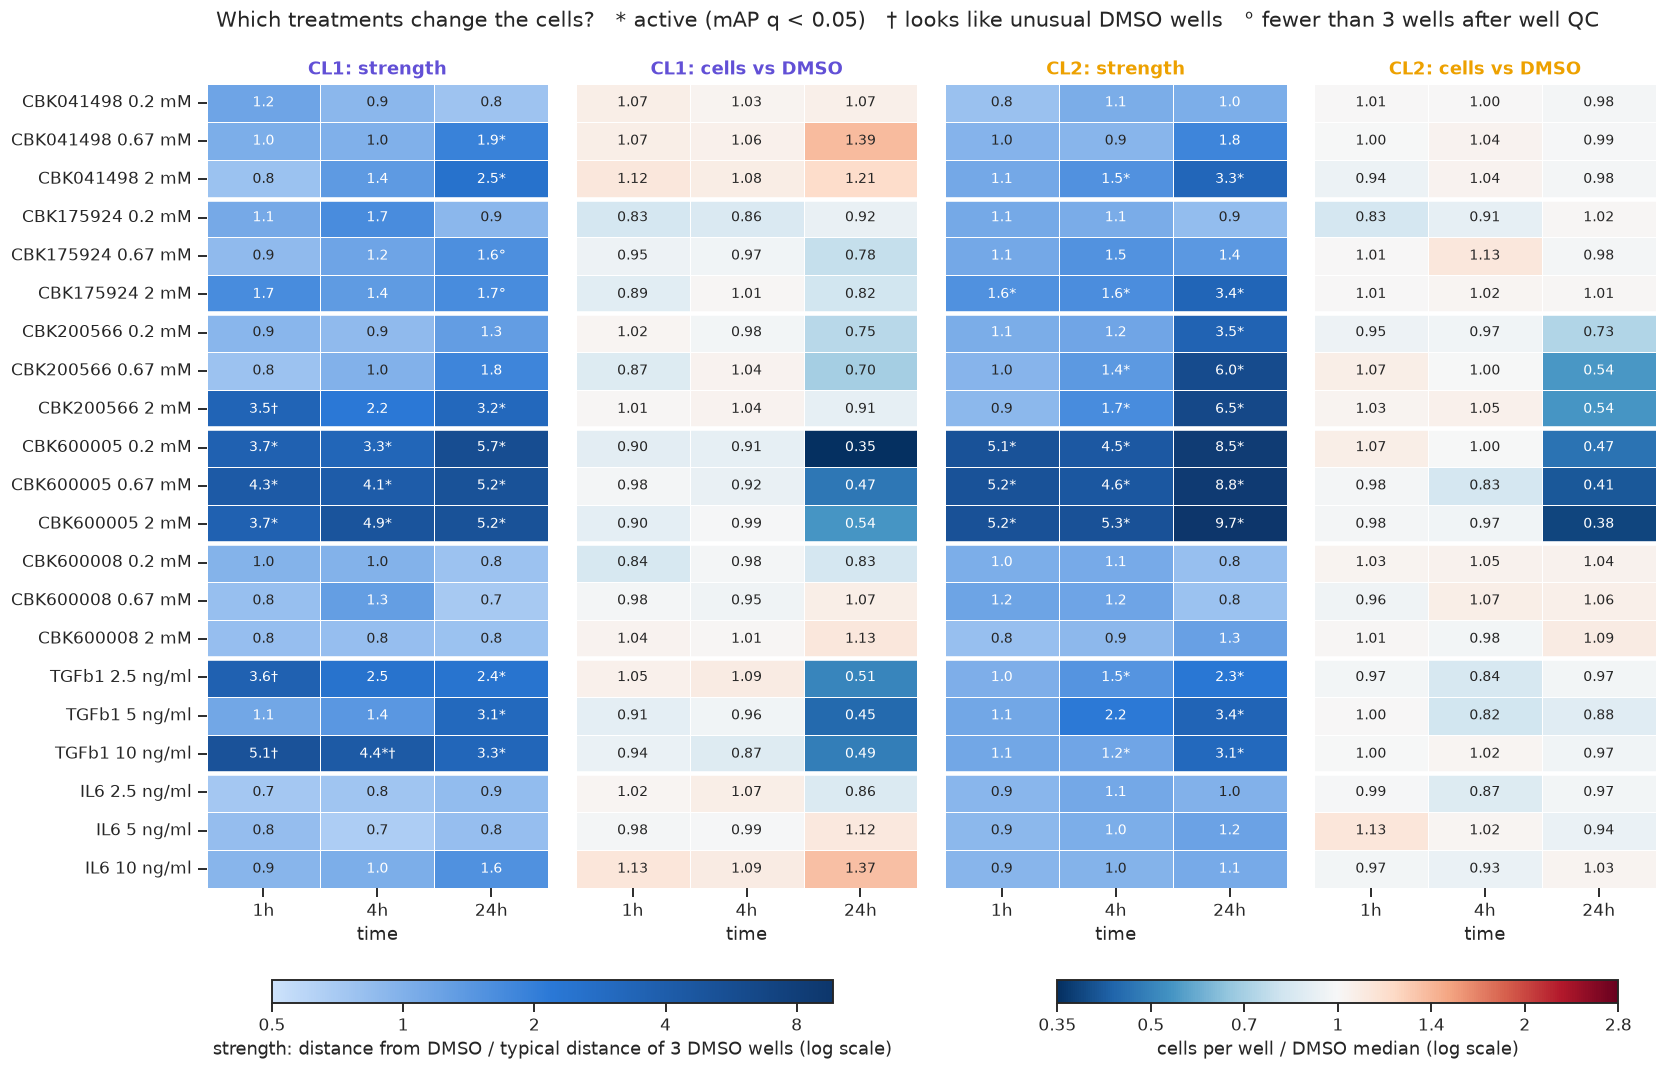

In [18]:
# figure: strength and cell count heatmaps (rows: treatment x dose, columns: time point)
fig, axes = plt.subplots(1, 4, figsize=(17, 9.5), gridspec_kw={"wspace": 0.08})
strength_norm = LogNorm(vmin=0.5, vmax=float(scores["strength"].max()))
cell_norm = TwoSlopeNorm(vmin=-1.5, vcenter=0, vmax=1.5)
for k, line in enumerate(line_order):
    sub = scores.filter(pl.col("cell_line") == line)
    lookup = {(r["perturbation"], r["time_point"]): r for r in sub.iter_rows(named=True)}
    missing = {"strength": np.nan, "cell_ratio": np.nan, "active": False, "looks_like_unusual_dmso": False}
    cell = lambda p, t: lookup.get((p, t), missing)
    strength = np.array([[cell(p, t)["strength"] for t in plate_order] for p in perturbation_order])
    cells = np.log2(np.array([[cell(p, t)["cell_ratio"] for t in plate_order] for p in perturbation_order]))
    # number, * when active, † when the treatment looks like the unusual DMSO wells, ° when well QC left fewer than 3 wells
    marks = np.array([
        [f"{cell(p, t)['strength']:.1f}" + ("*" if cell(p, t)["active"] else "") + ("†" if cell(p, t)["looks_like_unusual_dmso"] else "")
         + ("°" if (p, t) in lookup and lookup[(p, t)]["n_wells"] < 3 else "") if (p, t) in lookup else "" for t in plate_order]
        for p in perturbation_order
    ])
    cell_text = np.array([[f"{cell(p, t)['cell_ratio']:.2f}" if (p, t) in lookup else "" for t in plate_order] for p in perturbation_order])
    ax_s, ax_c = axes[2 * k], axes[2 * k + 1]
    sns.heatmap(strength, ax=ax_s, cmap=blues, norm=strength_norm, annot=marks, fmt="", cbar=False, linewidths=0.5, linecolor="white", annot_kws={"fontsize": 9})
    sns.heatmap(cells, ax=ax_c, cmap="RdBu_r", norm=cell_norm, annot=cell_text, fmt="", cbar=False, linewidths=0.5, linecolor="white", annot_kws={"fontsize": 9})
    ax_s.set_title(f"{line}: strength", fontsize=12, color=line_colors[line], fontweight="bold")
    ax_c.set_title(f"{line}: cells vs DMSO", fontsize=12, color=line_colors[line], fontweight="bold")
    for ax in (ax_s, ax_c):
        ax.set_xticklabels(plate_order, rotation=0)
        ax.set_xlabel("time")
        # separate the agents with white lines
        for boundary in range(3, len(perturbation_order), 3):
            ax.axhline(boundary, color="white", lw=3)
        if ax is axes[0]:
            ax.set_yticks(np.arange(len(perturbation_order)) + 0.5, [pretty(p) for p in perturbation_order], rotation=0)
        else:
            ax.set_yticks([])
strength_bar = fig.colorbar(plt.cm.ScalarMappable(norm=strength_norm, cmap=blues), cax=fig.add_axes([0.16, 0.0, 0.3, 0.022]), orientation="horizontal")
strength_bar.set_ticks([0.5, 1, 2, 4, 8], labels=["0.5", "1", "2", "4", "8"])
strength_bar.minorticks_off()
strength_bar.set_label("strength: distance from DMSO / typical distance of 3 DMSO wells (log scale)")
cell_bar = fig.colorbar(plt.cm.ScalarMappable(norm=cell_norm, cmap="RdBu_r"), cax=fig.add_axes([0.58, 0.0, 0.3, 0.022]), orientation="horizontal")
cell_bar.set_ticks([-1.5, -1, -0.5, 0, 0.5, 1, 1.5], labels=["0.35", "0.5", "0.7", "1", "1.4", "2", "2.8"])
cell_bar.set_label("cells per well / DMSO median (log scale)")
fig.suptitle("Which treatments change the cells?   * active (mAP q < 0.05)   † looks like unusual DMSO wells   ° fewer than 3 wells after well QC", fontsize=14, y=0.95)
save_figure(fig, "05_phenotypic-strength-heatmap")

**Result:**

- 40 of 126 tests are active (mAP q < 0.05): CBK600005 18 of 18, TGFβ1 9, CBK200566 6, CBK041498 4, CBK175924 3, CBK600008 0 and IL6 0 of 18.
- **CBK600005** is the strongest treatment: active at every dose, time and cell line (strength 3.3–9.7), strongest in CL2 at 24h (8.5–9.7). At 24h it lowers the cell count to 35–54% (CL1) and 38–47% (CL2) of DMSO: part of its effect may be toxicity.
- **TGFβ1 (positive control)** is active at all 3 doses in both cell lines at 24h (strength 2.3–3.4), and in CL2 already at 4h (2.5 and 10 ng/ml). In CL1 at 24h it also lowers the cell count to 45–51% of DMSO. Its high strength in CL1 at 1h (3.6 and 5.1) and 4h (4.4) comes with † (r = 0.91–0.98 with the unusual DMSO wells): this is mostly the plate-position effect. The only active test with † is TGFβ1 10 ng/ml at 4h in CL1.
- **IL6** is never active (strength 0.7–1.6), as expected. **CBK600008** is never active either (0.7–1.3).
- **CBK200566** is active at all doses in CL2 at 24h (3.5–6.5, cells 54–73% of DMSO), and at 2 mM in CL1 at 24h (3.2). **CBK041498** and **CBK175924** are active mainly at 2 mM, at 24h, and in CL2 also at 4h (CBK175924 2 mM in CL2 already at 1h).

## 5. Dose and time

For each agent, we follow the strength across the 3 doses and 3 time points. To test for a **dose response**, we correlate the distance of each of the 9 wells (3 doses × 3 replicates, fewer when a well failed QC) from the DMSO centre with the dose rank (Spearman ρ), per plate and cell line, and correct for the 42 tests (Benjamini–Hochberg). Time and exposure settings cannot be separated, so a trend in time can also come from the longer ER and AGP exposures of the 24h plate.

**Pass if:** TGFb1 gets stronger with time.

In [19]:
dose_rows = []
for time, line in panels:
    panel = meta.filter(panel_filter(time, line) & (pl.col("agent") != "DMSO"))
    for agent in agent_order:
        sub = panel.filter(pl.col("agent") == agent)
        rho, p_value = stats.spearmanr(sub["dose_level"], sub["distance"])
        medians = dict(sub.group_by("dose_level").agg(pl.col("distance").median()).iter_rows())
        dose_rows.append({"time_point": time, "cell_line": line, "agent": agent, "spearman_rho": rho, "pvalue": p_value,
                          "n_wells": sub.height, "median_distance_low": medians.get(0), "median_distance_mid": medians.get(1), "median_distance_high": medians.get(2)})
dose_response = pl.DataFrame(dose_rows).with_columns(pl.col("time_point").cast(pl.Enum(plate_order)))
dose_response = dose_response.with_columns(pl.Series("qvalue", stats.false_discovery_control(dose_response["pvalue"].to_numpy())))
dose_response = dose_response.with_columns(((pl.col("qvalue") < fdr) & (pl.col("spearman_rho") > 0)).alias("increases_with_dose"))
dose_response.write_csv(table_dir / "dose_response.csv")
with pl.Config(tbl_rows=50, tbl_width_chars=200):
    print(dose_response.filter(pl.col("pvalue") < 0.05).sort("agent", "cell_line", "time_point").with_columns(pl.selectors.float().round(3)))
print(f"increases with dose (q < {fdr}): {dose_response['increases_with_dose'].sum()} of {dose_response.height}")

# strength by time for the two ligands and the strongest compound
with pl.Config(tbl_rows=50, tbl_width_chars=200):
    print(
        scores.filter(pl.col("agent").is_in(["TGFb1", "IL6", "CBK600005"]))
        .with_columns(pl.col("strength").round(1).cast(pl.Utf8) + pl.when(pl.col("active")).then(pl.lit("*")).otherwise(pl.lit("")))
        .pivot(on="time_point", index=["cell_line", "perturbation"], values="strength")
        .sort("cell_line", pl.col("perturbation").replace_strict({p: i for i, p in enumerate(perturbation_order)}))
    )

shape: (7, 11)
┌────────────┬───────────┬───────────┬──────────────┬───┬─────────────────────┬──────────────────────┬────────┬─────────────────────┐
│ time_point ┆ cell_line ┆ agent     ┆ spearman_rho ┆ … ┆ median_distance_mid ┆ median_distance_high ┆ qvalue ┆ increases_with_dose │
│ ---        ┆ ---       ┆ ---       ┆ ---          ┆   ┆ ---                 ┆ ---                  ┆ ---    ┆ ---                 │
│ enum       ┆ str       ┆ str       ┆ f64          ┆   ┆ f64                 ┆ f64                  ┆ f64    ┆ bool                │
╞════════════╪═══════════╪═══════════╪══════════════╪═══╪═════════════════════╪══════════════════════╪════════╪═════════════════════╡
│ 24h        ┆ CL1       ┆ CBK041498 ┆ 0.843        ┆ … ┆ 49.665              ┆ 70.952               ┆ 0.06   ┆ false               │
│ 24h        ┆ CL2       ┆ CBK041498 ┆ 0.791        ┆ … ┆ 52.745              ┆ 83.883               ┆ 0.094  ┆ false               │
│ 24h        ┆ CL2       ┆ CBK175924 ┆ 0.791   

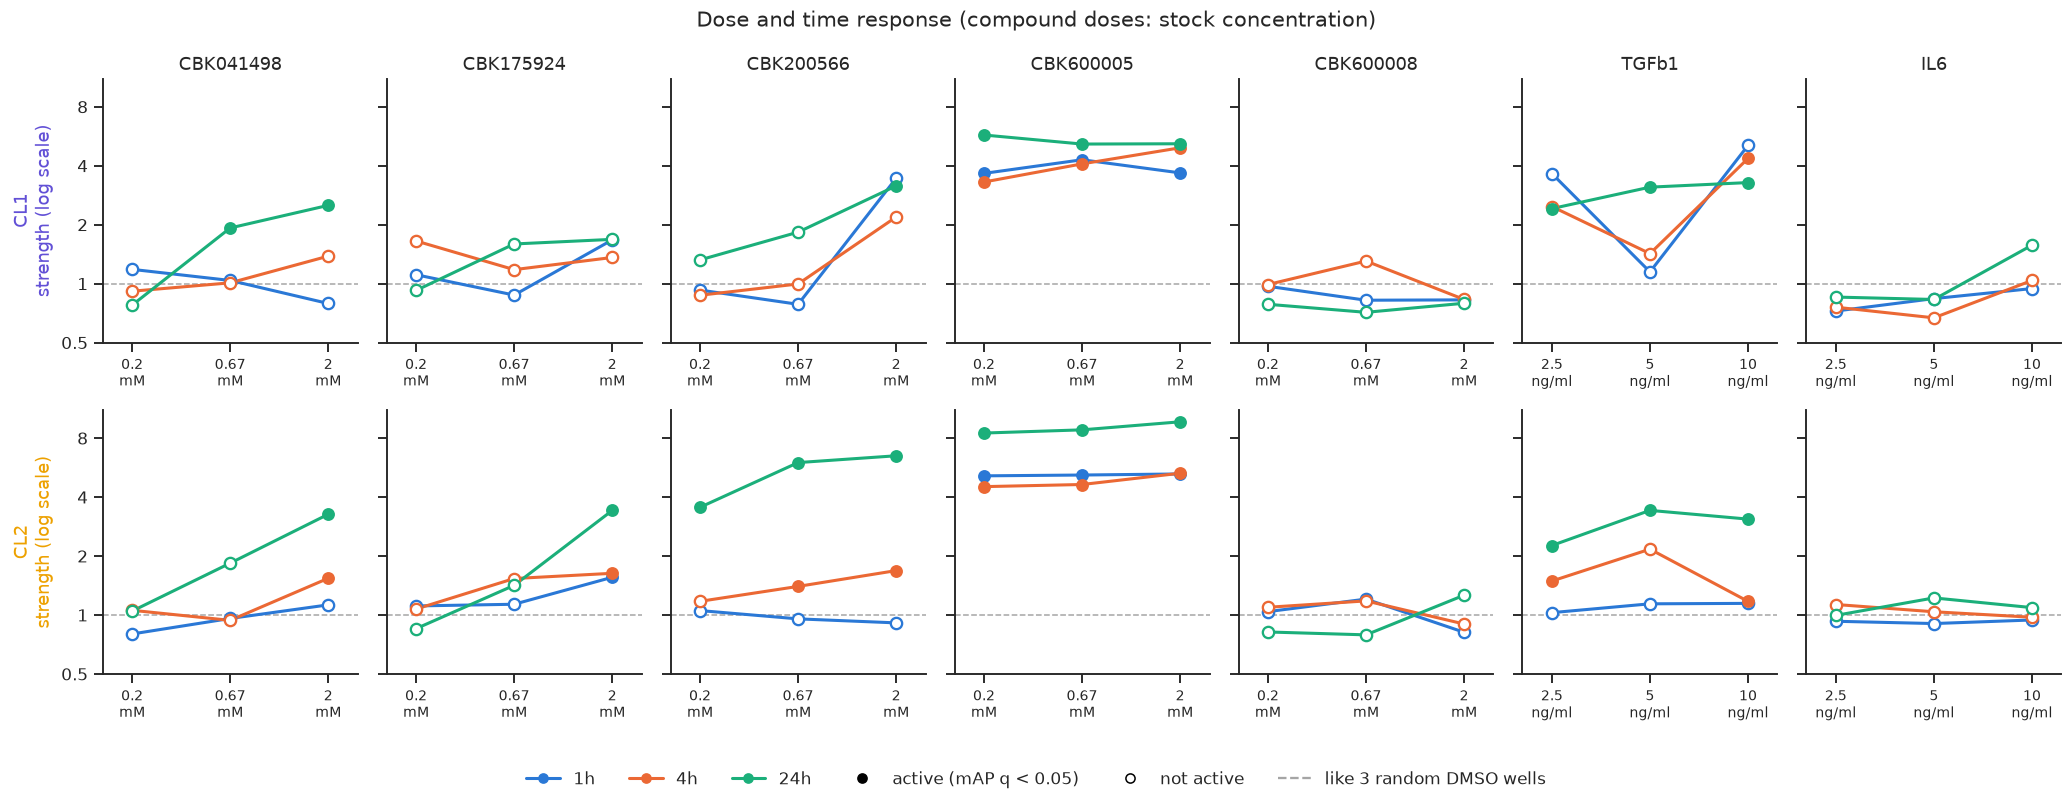

In [20]:
# figure: strength by dose (x) and time (lines), per agent and cell line
fig, axes = plt.subplots(2, len(agent_order), figsize=(19, 7), sharey=True)
for i, line in enumerate(line_order):
    for j, agent in enumerate(agent_order):
        ax = axes[i, j]
        ax.axhline(1, color="#a5a5a5", ls="--", lw=1)
        for time in plate_order:
            sub = scores.filter((pl.col("agent") == agent) & (pl.col("cell_line") == line) & (pl.col("time_point") == time)).sort("dose_level")
            ax.plot(sub["dose_level"], sub["strength"], color=plate_colors[time], lw=2, zorder=2)
            active = sub["active"].to_numpy()
            ax.scatter(sub["dose_level"].to_numpy()[active], sub["strength"].to_numpy()[active], color=plate_colors[time], s=55, zorder=3)
            ax.scatter(sub["dose_level"].to_numpy()[~active], sub["strength"].to_numpy()[~active], facecolor="white", edgecolor=plate_colors[time], lw=1.5, s=55, zorder=3)
        ax.set_yscale("log")
        ax.set_yticks([0.5, 1, 2, 4, 8], ["0.5", "1", "2", "4", "8"])
        ax.minorticks_off()
        ax.set_xticks([0, 1, 2], [dose_text[d].replace(" ", "\n") for d in dose_order[agent]], fontsize=9)
        ax.set_xlim(-0.3, 2.3)
        if i == 0:
            ax.set_title(agent, fontsize=12)
        if j == 0:
            ax.set_ylabel(f"{line}\nstrength (log scale)", fontsize=12, color=line_colors[line])
handles = [Line2D([], [], color=plate_colors[t], lw=2, marker="o", label=t) for t in plate_order] + [
    Line2D([], [], marker="o", ls="", color="black", label="active (mAP q < 0.05)"),
    Line2D([], [], marker="o", ls="", markerfacecolor="white", markeredgecolor="black", label="not active"),
    Line2D([], [], color="#a5a5a5", ls="--", label="like 3 random DMSO wells"),
]
fig.legend(handles=handles, loc="lower center", ncol=6, frameon=False, bbox_to_anchor=(0.5, -0.05))
fig.suptitle("Dose and time response (compound doses: stock concentration)", fontsize=14)
fig.tight_layout(rect=(0, 0.03, 1, 1))
save_figure(fig, "06_dose-and-time-response")

**Result:**

- Only 1 of 42 dose tests is significant after correction: CBK600005 in CL1 at 4h (ρ = 0.95, q = 0.004). With 3 doses × 3 wells the test has little power. CBK041498 (both cell lines) and CBK175924 (CL2) at 24h rise with dose (ρ = 0.79–0.84, p < 0.05, q = 0.06–0.09).
- CBK600005 is already at full strength at the lowest stock dose (0.2 mM): its curve is flat, so the tested doses are probably all above saturation.
- Most active agents are strongest at 24h. TGFβ1 in CL2 grows with time (1.0–1.1 at 1h, 1.2–2.2 at 4h, 2.3–3.4 at 24h), with the medium dose (5 ng/ml) furthest from DMSO at 4h and 24h: no clean dose response. In CL1, TGFβ1 is only clean at 24h (2.4, 3.1, 3.3 from low to high dose).
- IL6 stays near DMSO (0.7–1.6) at all doses and times. Remember that the 24h plate also had longer ER and AGP exposures.

## 6. Which treatments look alike?

We take the consensus profiles of the active treatments (mAP q < 0.05) and correlate every pair (Pearson r over all features). Treatments with a similar effect on the cells correlate strongly; the clustering puts them next to each other. Treatments marked † look like the unusual DMSO wells of their plate (section 3a).

In [21]:
active = scores.filter(pl.col("active")).sort("agent", "cell_line", "time_point", "dose_level")
consensus = np.vstack([
    np.median(profiles[meta.filter(panel_filter(r["time_point"], r["cell_line"]) & (pl.col("Metadata_Perturbation") == r["perturbation"]))["row"].to_numpy()], axis=0)
    for r in active.iter_rows(named=True)
])
names = [
    f"{pretty(r['perturbation'])} · {r['time_point']} · {r['cell_line']}" + (" †" if r["looks_like_unusual_dmso"] else "")
    for r in active.iter_rows(named=True)
]
similarity = np.corrcoef(consensus)
pl.DataFrame(similarity, schema=names).insert_column(0, pl.Series("treatment", names)).write_csv(table_dir / "active_consensus_correlation.csv")

# how alike are treatments of the same agent, compared with different agents?
agents = active["agent"].to_numpy()
upper = np.triu_indices(len(names), 1)
same = agents[upper[0]] == agents[upper[1]]
print(f"{len(names)} active treatments; median r between them: same agent {np.median(similarity[upper][same]):.2f} ({same.sum()} pairs), different agents {np.median(similarity[upper][~same]):.2f} ({(~same).sum()} pairs)")
for agent in agent_order:
    pick = agents == agent
    if pick.sum() >= 2:
        block = similarity[np.ix_(pick, pick)][np.triu_indices(pick.sum(), 1)]
        print(f"  {agent}: {pick.sum()} active, median r within {np.median(block):.2f}")
# most similar pairs of different agents
pairs = sorted(((similarity[a, b], names[a], names[b]) for a, b in zip(*upper) if agents[a] != agents[b]), reverse=True)[:8]
print("most similar pairs of different agents:")
for r, a, b in pairs:
    print(f"  r = {r:.2f}: {a}  vs  {b}")

40 active treatments; median r between them: same agent 0.36 (213 pairs), different agents -0.06 (567 pairs)
  CBK041498: 4 active, median r within 0.38
  CBK175924: 3 active, median r within 0.70
  CBK200566: 6 active, median r within 0.34
  CBK600005: 18 active, median r within 0.37
  TGFb1: 9 active, median r within 0.31
most similar pairs of different agents:
  r = 0.50: CBK175924 2 mM · 1h · CL2  vs  TGFb1 10 ng/ml · 24h · CL2
  r = 0.49: CBK041498 2 mM · 24h · CL1  vs  CBK600005 2 mM · 24h · CL1
  r = 0.47: CBK600005 2 mM · 24h · CL2  vs  TGFb1 5 ng/ml · 24h · CL2
  r = 0.47: CBK200566 2 mM · 24h · CL1  vs  TGFb1 10 ng/ml · 4h · CL1 †
  r = 0.46: CBK175924 2 mM · 1h · CL2  vs  TGFb1 10 ng/ml · 4h · CL2
  r = 0.44: CBK600005 0.2 mM · 24h · CL2  vs  TGFb1 10 ng/ml · 24h · CL2
  r = 0.43: CBK200566 0.67 mM · 4h · CL2  vs  CBK600005 2 mM · 4h · CL1
  r = 0.42: CBK600005 0.67 mM · 24h · CL2  vs  TGFb1 5 ng/ml · 24h · CL2


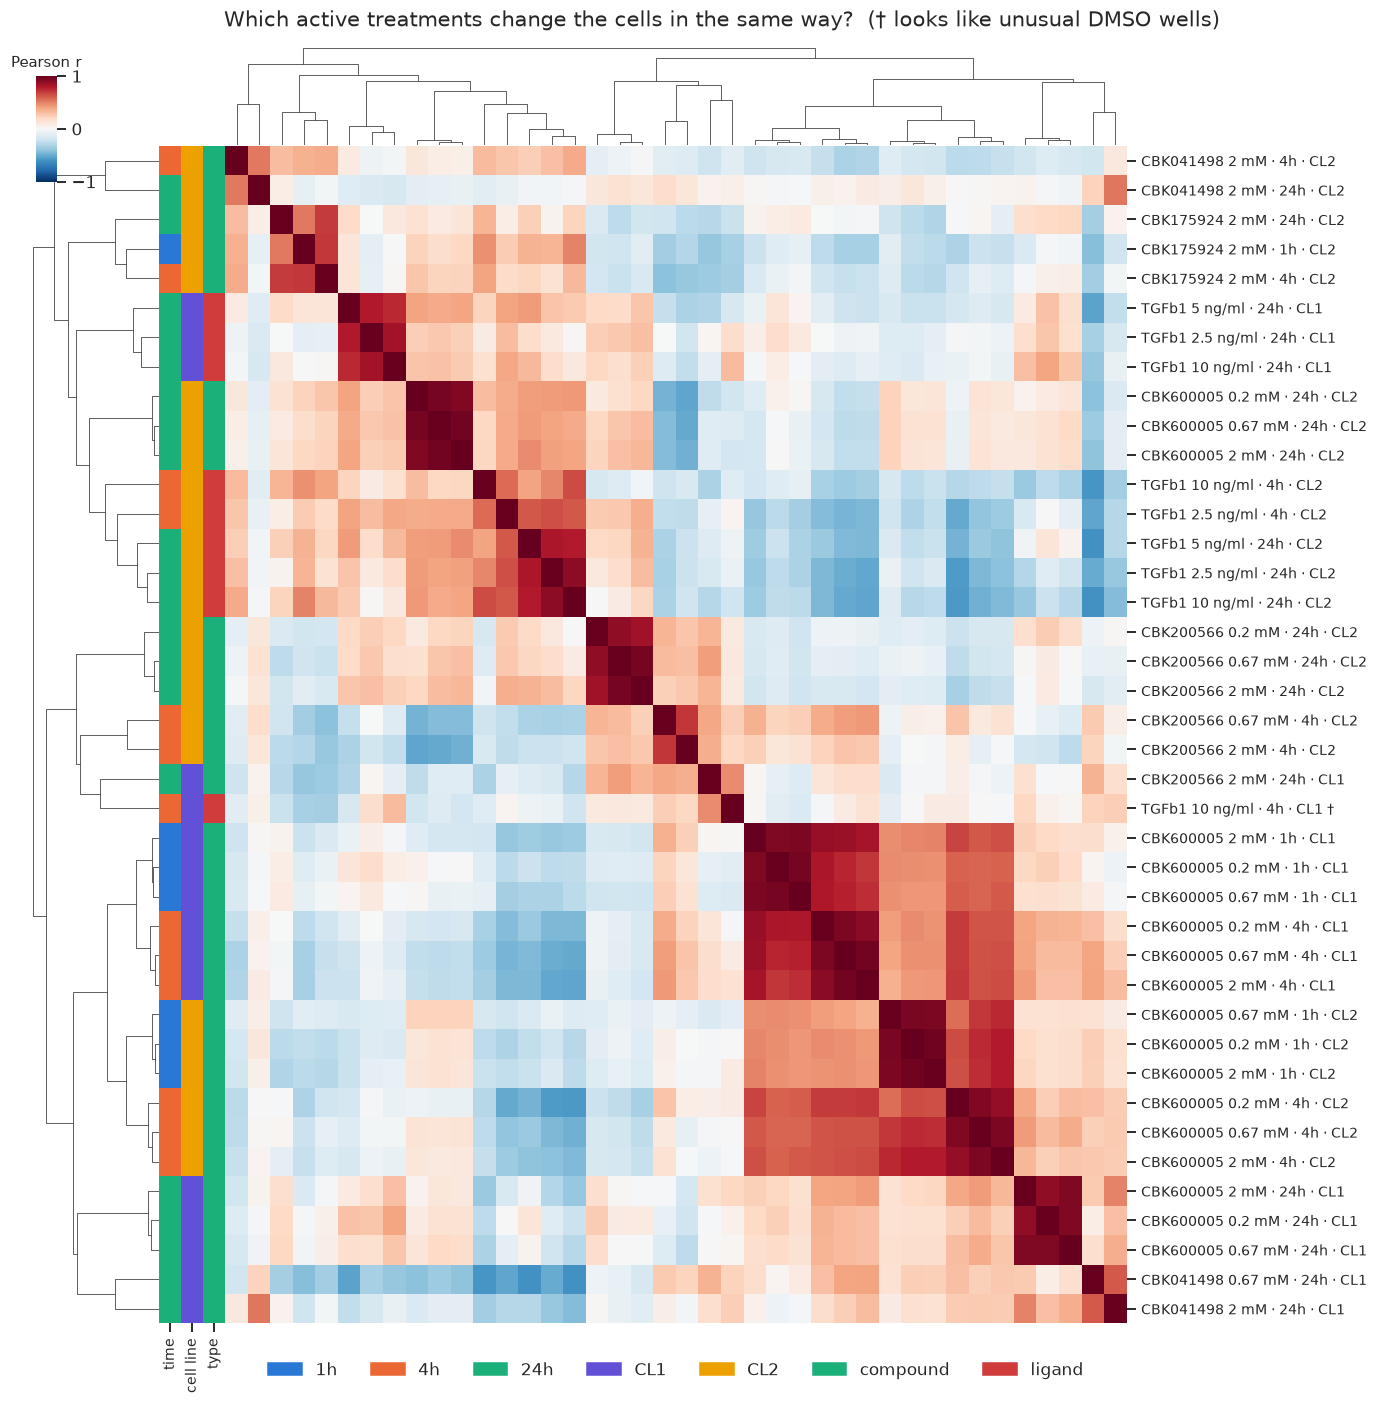

In [22]:
# figure: clustered correlation heatmap of the active consensus profiles
linkage = hierarchy.linkage(squareform(1 - similarity, checks=False), method="average")
row_colors = [
    [plate_colors[t] for t in active["time_point"].cast(pl.Utf8)],
    [line_colors[c] for c in active["cell_line"]],
    [well_type_colors[w] for w in active["well_type"]],
]
grid = sns.clustermap(
    similarity, row_linkage=linkage, col_linkage=linkage, cmap="RdBu_r", vmin=-1, vmax=1, center=0,
    row_colors=row_colors, xticklabels=False, yticklabels=names, figsize=(13, 12),
    dendrogram_ratio=(0.12, 0.08), colors_ratio=0.02, cbar_pos=(0.02, 0.88, 0.015, 0.08),
)
grid.ax_cbar.set_title("Pearson r", fontsize=10)
grid.ax_heatmap.set_yticklabels(grid.ax_heatmap.get_yticklabels(), fontsize=9)
grid.ax_row_colors.set_xticks([0.5, 1.5, 2.5], ["time", "cell line", "type"], rotation=90, fontsize=9)
handles = (
    [Patch(color=plate_colors[t], label=t) for t in plate_order]
    + [Patch(color=line_colors[c], label=c) for c in line_order]
    + [Patch(color=well_type_colors[w], label=w) for w in ["compound", "ligand"]]
)
grid.ax_heatmap.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=7, frameon=False)
grid.figure.suptitle("Which active treatments change the cells in the same way?  († looks like unusual DMSO wells)", fontsize=14, y=1.01)
grid.savefig(fig_dir / "07_active-treatment-similarity.png", dpi=200, bbox_inches="tight")
plt.show()

### Which feature groups change most?

For the strongest active treatment of each agent and cell line (leaving out †), we average the absolute rescaled values of the consensus profile within each compartment × channel group (e.g. all cytoplasm ER features). Shape features have no channel; colocalization features use two channels.

In [23]:
var = adata.var.reset_index()
channel_names = {"CorrDNA": "DNA", "CorrRNA": "RNA", "CorrER": "ER", "CorrAGP": "AGP", "CorrMito": "Mito"}
channel_of = [
    "Shape" if not isinstance(c, str) else ("Coloc." if "|" in c else channel_names[c])
    for c in var["channel"]
]
group_of = np.array([f"{o} · {c}" for o, c in zip(var["object"], channel_of)])
group_order = [f"{o} · {c}" for o in ["Cells", "Cytoplasm", "Nuclei"] for c in ["DNA", "RNA", "ER", "AGP", "Mito", "Shape", "Coloc."]]
group_order = [g for g in group_order if g in set(group_of)]

# the strongest active treatment of each agent and cell line, leaving out the ones that look like unusual DMSO wells
top = (
    active.filter(~pl.col("looks_like_unusual_dmso"))
    .sort("strength", descending=True)
    .group_by("agent", "cell_line", maintain_order=True)
    .first()
    .sort("cell_line", pl.col("agent").replace_strict({a: i for i, a in enumerate(agent_order)}))
)
index_of = {(r["perturbation"], r["time_point"], r["cell_line"]): i for i, r in enumerate(active.iter_rows(named=True))}
top_rows = [index_of[(r["perturbation"], r["time_point"], r["cell_line"])] for r in top.iter_rows(named=True)]
group_change = np.array([[np.abs(consensus[i, group_of == g]).mean() for g in group_order] for i in top_rows])
top_names = [names[i] for i in top_rows]
feature_groups = pl.DataFrame(group_change, schema=group_order).insert_column(0, pl.Series("treatment", top_names))
feature_groups.write_csv(table_dir / "feature_group_change_top_active.csv")
print("features per group:", {g: int((group_of == g).sum()) for g in group_order})
for name, row in zip(top_names, group_change):
    best = np.argsort(row)[::-1][:3]
    print(f"  {name}: " + ", ".join(f"{group_order[b]} {row[b]:.1f}" for b in best))

features per group: {'Cells · DNA': 65, 'Cells · RNA': 68, 'Cells · ER': 67, 'Cells · AGP': 62, 'Cells · Mito': 66, 'Cells · Shape': 43, 'Cells · Coloc.': 47, 'Cytoplasm · DNA': 75, 'Cytoplasm · RNA': 77, 'Cytoplasm · ER': 86, 'Cytoplasm · AGP': 81, 'Cytoplasm · Mito': 80, 'Cytoplasm · Shape': 32, 'Cytoplasm · Coloc.': 55, 'Nuclei · DNA': 70, 'Nuclei · RNA': 86, 'Nuclei · ER': 86, 'Nuclei · AGP': 81, 'Nuclei · Mito': 79, 'Nuclei · Shape': 39, 'Nuclei · Coloc.': 54}
  CBK041498 2 mM · 24h · CL1: Nuclei · Coloc. 1.8, Cells · DNA 1.6, Cytoplasm · DNA 1.5
  CBK200566 2 mM · 24h · CL1: Nuclei · DNA 2.7, Cytoplasm · DNA 2.4, Cells · DNA 2.4
  CBK600005 0.2 mM · 24h · CL1: Nuclei · Shape 5.1, Cells · Shape 4.5, Cytoplasm · Shape 4.0
  TGFb1 10 ng/ml · 24h · CL1: Nuclei · ER 2.8, Cells · ER 2.7, Cytoplasm · ER 2.4
  CBK041498 2 mM · 24h · CL2: Cells · Mito 2.8, Cytoplasm · Mito 2.5, Cytoplasm · Coloc. 2.1
  CBK175924 2 mM · 24h · CL2: Cytoplasm · Mito 3.3, Cells · Mito 2.8, Cytoplasm · AGP 2.7

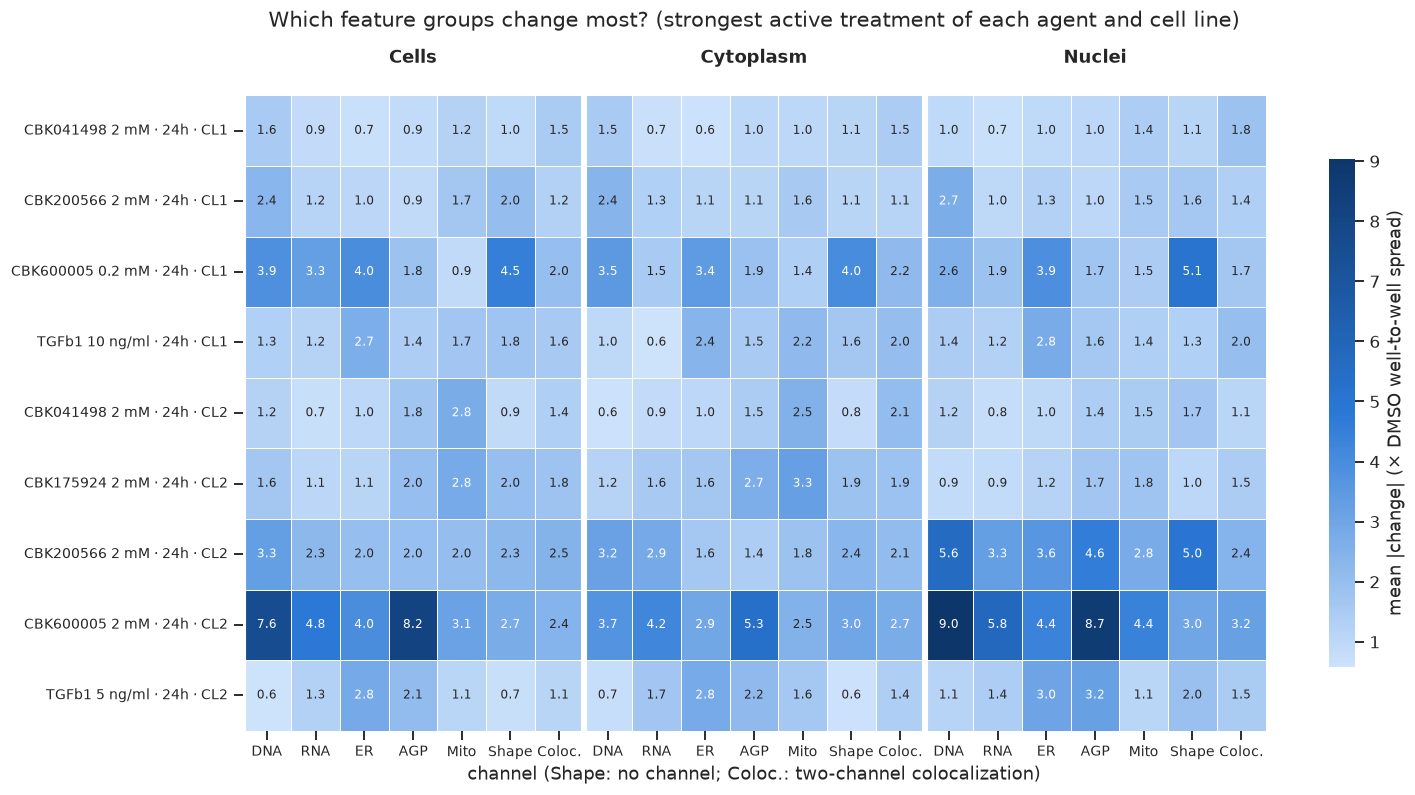

In [24]:
# figure: mean absolute change per compartment x channel for the strongest active treatments
fig, ax = plt.subplots(figsize=(15, 7.5))
sns.heatmap(
    group_change, ax=ax, cmap=blues, annot=True, fmt=".1f", annot_kws={"fontsize": 8},
    linewidths=0.5, linecolor="white", cbar_kws={"label": "mean |change| (× DMSO well-to-well spread)", "shrink": 0.8},
)
ax.set_yticks(np.arange(len(top_names)) + 0.5, top_names, rotation=0, fontsize=9)
ax.set_xticks(np.arange(len(group_order)) + 0.5, [g.split(" · ")[1] for g in group_order], rotation=0, fontsize=9)
# compartment labels above the columns, separated by white lines
compartments = [g.split(" · ")[0] for g in group_order]
for compartment in ["Cells", "Cytoplasm", "Nuclei"]:
    cols = [k for k, c in enumerate(compartments) if c == compartment]
    ax.text(np.mean(cols) + 0.5, -0.4, compartment, ha="center", va="bottom", fontsize=12, fontweight="bold")
    ax.axvline(cols[0], color="white", lw=4)
ax.set_xlabel("channel (Shape: no channel; Coloc.: two-channel colocalization)")
ax.set_title("Which feature groups change most? (strongest active treatment of each agent and cell line)", fontsize=14, pad=45)
save_figure(fig, "08_feature-groups-strongest-treatments")

**Result:**

- Among the 40 active treatments, those of the same agent correlate more (median r = 0.36) than those of different agents (median r = −0.06). The doses of one compound at one time point are nearly identical (CBK600005: median r = 0.93–0.95 within each time and cell line; CBK200566 in CL2 at 24h: 0.89; TGFβ1 at 24h: 0.80–0.82): dose changes the size of the effect, not its direction.
- The two cell lines respond differently: CBK600005 correlates r = 0.46 between CL1 and CL2 at 1h, 0.64 at 4h, but only 0.13 at 24h; TGFβ1 at 24h r = 0.19.
- No two different compounds look alike: the most similar pair of different agents reaches only r = 0.50 (CBK175924 2 mM 1h CL2 vs TGFβ1 10 ng/ml 24h CL2). TGFβ1 in CL2 shares part of its profile with CBK600005 at 24h in CL2 (median r = 0.42).
- Feature groups: CBK600005 at 24h changes nuclear DNA and AGP features most in CL2 (mean |change| 9.0 and 8.7) and cell and nuclear shape in CL1 (5.1); CBK200566 mainly DNA features (2.7 in CL1; nuclear DNA 5.6 and shape 5.0 in CL2); TGFβ1 mostly ER and AGP (2.7–3.2); CBK041498 and CBK175924 in CL2 mostly Mito (2.8–3.3). ER and AGP changes at 24h may partly reflect the longer exposures of that plate, although every comparison is against DMSO of the same plate.

In [25]:
# the main table: one row per treatment x plate x cell line
scores.sort("cell_line", "time_point", pl.col("perturbation").replace_strict({p: i for i, p in enumerate(perturbation_order)})).write_csv(
    table_dir / "treatment_scores.csv"
)
print(sorted(p.name for p in table_dir.iterdir()))
print(sorted(p.name for p in fig_dir.iterdir()))

['active_consensus_correlation.csv', 'dmso_well_health.csv', 'dose_response.csv', 'failed_qc_wells.csv', 'feature_group_change_top_active.csv', 'map_control_references.csv', 'outlier_replicates.csv', 'panel_summary.csv', 'replicate_well_health.csv', 'replicating_doses.csv', 'treatment_scores.csv']
['01_replicate-correlation-vs-null.png', '02_reproducibility-summary.png', '02b_map-negative-vs-positive-reference.png', '03_plate-maps-distance-from-dmso.png', '04_replicate-spread-and-outliers.png', '05_phenotypic-strength-heatmap.png', '06_dose-and-time-response.png', '07_active-treatment-similarity.png', '08_feature-groups-strongest-treatments.png']


## Summary

**Data:** 1,136 QCed well profiles (1,399 features; 4 wells left out by well QC) from 3 plates (1h, 4h, 24h) × 2 cell lines; 21 treatments × 3 replicate wells and 127 DMSO wells per plate and cell line.

**What we did:** clipped extreme values at ±20 and rescaled each feature to the DMSO well-to-well spread; measured replicate agreement for each compound and dose (percent replicating against a non-replicate null) and activity (mAP against DMSO, q < 0.05), with DMSO-only negative control checks; checked the DMSO wells across the plate; flagged outlier replicate wells; measured the strength of each treatment, dose and time trends, and similarity between active treatments.

**Findings:**

- Reproducibility grows with time: percent replicating 19% / 19% at 1h, 33% / 43% at 4h, 33% / 57% at 24h (CL1 / CL2); 40 of 126 tests active by mAP. DMSO checks are at chance (about 5%; 3.3% for mAP).
- Doses: CBK600005 works at all 3 doses, already at 0.2 mM; CBK041498, CBK175924 and CBK600008 only at 2 mM; CBK200566 (CL2) and TGFβ1 (CL2, 24h) also at lower doses.
- CL1 at 1h and 4h has a strong plate-position effect: 33 (1h) and 11 (4h) of 127 DMSO wells are shifted, all in odd rows of columns 1–6. At 24h, low-cell wells in rows M–N (both lines), columns 3–4 (CL1) and columns 20–22 (CL2) are shifted. These explain most outlier replicates and the apparent TGFβ1 effect in CL1 at 1h and 4h.
- 48 of 372 treated wells (13%) are outlier replicates, many in the shifted areas or with few cells.
- CBK600005 is active in all 18 tests (strength up to 9.7), flat across doses, and halves the cell count at 24h (35–54% of DMSO): strong effect, possibly with toxicity.
- TGFβ1 (positive control) is active at all doses at 24h in both lines and grows with time in CL2; no clean dose response (5 ng/ml strongest in CL2). IL6 and CBK600008 are never active.
- CBK200566 is strongly active in CL2 at 24h (all doses); CBK041498 and CBK175924 are active mainly at 2 mM.
- Doses of one compound share one profile; different compounds do not look alike (r ≤ 0.50); the two cell lines respond differently to the same treatment (e.g. r = 0.13 for CBK600005 at 24h).

**Caveats:**

- Time is confounded with exposure (24h plate: longer ER and AGP exposures), and cell line with plate side.
- Compound doses are stock concentrations; final concentrations are unknown.
- Only 3 replicates and 3 doses: dose tests have little power, and one bad well changes a result.
- The plate-position effects are not corrected here; the "looks like unusual DMSO" flag (r ≥ 0.8) is a simple screen, not a correction.
- Cell count changes (24h) can drive many features; see the cell count notebook before reading those profiles as morphology.